# <div align="center">TRABALHO DE ECAC</div>

## Trabalho realizado por:
- Luis Nogueira
- Alicia
- Sofia

# DATASET, DATA UNDERSTANDING AND EXPLATORY ANALYSIS

## The Dataset
Foi nos disponibilizada metadata de músicas. Esta continha linhas com informação incompleta (colunas não preenchidas) que, ao importármos toda a data, foram logo de seguida, separadas, tal como pedido no enunciado.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df_metadata = pd.read_csv('merge_ecac/metadata.csv')
df_test_keys = pd.read_csv('merge_ecac/test_songs.csv')

is_test = df_metadata['Audio_Song'].isin(df_test_keys['Audio_Song'])

df_train_dev = df_metadata[~is_test].copy()
df_test = df_metadata[is_test].copy()

print(f"Conjunto de treino/desenvolvimento: {len(df_train_dev)} linhas")
print(f"Conjunto de teste isolado: {len(df_test)} linhas")


932 linhas - Este é o tamanho do conjunto de formação e de desenvolvimento (df_train_dev). Aqui será realizada a análise exploratória, a limpeza de dados e o treino dos modelos.

416 linhas - corresponde ao tamanho do conjunto de teste isolado (df_test), que inclui 409 músicas de teste do MERGE e sete duplicados, ficando congelado até à avaliação final.

### Contagens e Tabela do split de dados

A partição de teste engloba as 409 músicas pertencentes ao split oficial de 31% do dataset MERGE. Devido à injeção deliberada de ruído no dataset (Defeito A1: 25 linhas duplicadas exatas em metadata.csv), o filtro resulta em 416 linhas no conjunto de teste.

<div style="text-align: center; display: flex; justify-content: center;">

| Conjunto de Dados | Variável | Total de Linhas | Músicas Únicas | Duplicados | Função no Projeto |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **Treino & Dev** | `df_train_dev` | **932** | 914 | 18 | Limpeza, EDA e Treino com Validação Cruzada |
| **Teste Isolado** | `df_test` | **416** | 409 | 7 | Avaliação final congelada |
| **Total Global** | `df_metadata` | **1 348** | 1 323 | 25 | Total de registos em metadata.csv |

</div>


### Data Understanding

#### 2.1

Cada coluna contem um tipo de informação descritiva para cada música. As 27 colunas do ficheiro metadata.cvs dividem-se nas seguintes categorias funcionais:

**Indentifiers:** Chaves primarias e códigos de ligação aos ficheiros de audio, texto de letras e base de dados editorial. Nao tem valos preditivo numérico.

Audio_Song, Lyric_Song, AppearancesTrackIDs, AppearencesAlbumIDs

**Administrative:** Metadata de controlo de recolha de dados e links para pre-escuta de audio.

AllMusic Extraction Date, SamplURL

**Measurements and Descriptive:** Atributos quantitativos e numéricos

Duration, Relevance, Year, LowestYear, ActualYear, num_Genres, num_MoodsAll

**Content/Metadata Tags:** Rotulos editoriais textuais e respetivos do AllMusic sobre e conteudo, genero, estilo e clima da musica.

Song, Artist, Album, Genres, GenreWeights, Styles, StyleWeights, Themes, ThemeWeights, Moods, MoodsAll, MoodsAllWeights, Sample



**Target : Quadrant**

Q1, Q2, Q3, Q4 correspondentes aos quatro quadrantes do plano Valencia - Arousal.

#### 2.2

Não, as quatro fontes de dados nao se cruzam numa relação estrita de um-para-um. A quebra de relação ocorre:

Metadata to Audio and Lyrics:

Devido à presença de 25 linhas duplicadas exatas no metadat.csv (Defeito A1), a relação passa de 1:1 para N:1. Existem 1348 linhas em metada.csv para apenas 1323 musicas Audio_Song.

Metadata to Album Covers:

A relação quebra devido a falhas de cobertura para albuns sem capa disponivel e a ediçoes do mesmo album que partilham a mesma imagem.

O que decorre/resulta dessa quebra é a duplicação indesejada, Data Leakage e dados multimodais imcompleto.

#### 2.3

As lista de colunas suspeitas de Target Leakage são Moods, MoodsAll, MoodsAll, MoodsAllWeights, Theme e Styles. Estas colunas devem ser marcadas para remoção do conjunto de features preditivas, pois na aplicação real do modelo em novas faixas de audio/letra, estas tags manuais do AllMusic não estarão disponiveis.

## 3. EXPLORATORY ANALYSIS

#### 3.1

O código abaixo tem um output que descreve a avaliação da distribuição da variavel alvo, na indentificação de padroes de valores em falta e na inspeção da amplitude das caracteristicas quantitativas.

Adicionalmente, o código converte os anos das colunas `Year`, `LowestYear` e `ActualYear` para formato numérico (para calcular corretamente o mínimo, máximo, mediana, média e desvio padrão) e gera as visualizações das distribuições pedidas na análise exploratória: um gráfico de barras para ilustrar o desequilíbrio entre os quatro quadrantes emocionais (`Quadrant`), histogramas com curva de densidade (KDE) e *boxplots* lado a lado para avaliar a forma, assimetria e dispersão de cada variável numérica (aplicando um filtro visual temporário aos erros extremos como `-1`, `0`, `9999` e `367000` para não esmagar a escala dos gráficos) e, por fim, uma matriz de dispersão (*pairplot*) para inspecionar as relações conjuntas entre pares de variáveis por classe.

In [ ]:
# Percentagem de cada quadrante
percentagem = df_train_dev['Quadrant'].value_counts(normalize=True) * 100
contagem = df_train_dev['Quadrant'].value_counts()

# Juntar num único quadro
resumo_target = pd.DataFrame({
    'Total de Músicas': contagem,
    'Percentagem (%)': percentagem.round(2)
})

print("    Distribuição da Variável Alvo (Quadrant)    ")
print(resumo_target)

# Analise de valores em falta 
nulos_abs = df_train_dev.isnull().sum()
nulos_pct = (df_train_dev.isnull().sum() / len(df_train_dev)) * 100

resumo_nulos = pd.DataFrame({
    "Valores Nulos" : nulos_abs,
    "Percentagem": nulos_pct.round(2)
})

resumo_nulos = resumo_nulos[resumo_nulos["Valores Nulos"] > 0]

print("\n Colunas com Valores em Falta  ")
print(resumo_nulos)

cols_num = ['Duration', 'Relevance', 'Year', 'LowestYear', 'ActualYear', 'num_Genres', 'num_MoodsAll']

resumo_escala = df_train_dev[cols_num].agg(['min', 'max']).T

print("\n    Resumo Estatístico das Variáveis Numéricas    ")
print(resumo_escala.round(2))

# Configurar o estilo visual
sns.set_theme(style="whitegrid")

# ============================================================
# SEPARAÇÃO TREINO/DEV VS. TESTE
# ============================================================

is_test = df_metadata['Audio_Song'].isin(df_test_keys['Audio_Song'])

df_train_dev = df_metadata[~is_test].copy()
df_test = df_metadata[is_test].copy()

print(f"Conjunto de treino/desenvolvimento: {len(df_train_dev)} linhas")
print(f"Conjunto de teste isolado: {len(df_test)} linhas")

# ============================================================
# TABELAS DE RESUMO (ALVO, NULOS E ESCALA)
# ============================================================
percentagem = df_train_dev['Quadrant'].value_counts(normalize=True) * 100
contagem = df_train_dev['Quadrant'].value_counts()

resumo_target = pd.DataFrame({
    'Total de Músicas': contagem,
    'Percentagem (%)': percentagem.round(2)
})

print("\n    Distribuição da Variável Alvo (Quadrant)    ")
print(resumo_target)

# Análise de valores em falta
nulos_abs = df_train_dev.isnull().sum()
nulos_pct = (df_train_dev.isnull().sum() / len(df_train_dev)) * 100

resumo_nulos = pd.DataFrame({
    "Valores Nulos": nulos_abs,
    "Percentagem": nulos_pct.round(2)
})
resumo_nulos = resumo_nulos[resumo_nulos["Valores Nulos"] > 0]

print("\n Colunas com Valores em Falta  ")
print(resumo_nulos)

# Preparar cópia numérica para que Year, LowestYear e ActualYear
# calculem o min/max numérico (e não por ordem alfabética de texto)
cols_num = ['Duration', 'Relevance', 'Year', 'LowestYear', 'ActualYear', 'num_Genres', 'num_MoodsAll']
df_num_plot = df_train_dev[cols_num + ['Quadrant']].copy()

for col_ano in ['Year', 'LowestYear']:
    df_num_plot[col_ano] = (
        df_num_plot[col_ano]
        .astype(str)
        .str.extract(r'(\d{4})')[0]
    )
    df_num_plot[col_ano] = pd.to_numeric(df_num_plot[col_ano], errors='coerce')

df_num_plot['ActualYear'] = pd.to_numeric(df_num_plot['ActualYear'], errors='coerce')

resumo_escala = df_num_plot[cols_num].agg(['min', 'max', 'median', 'mean', 'std']).T

print("\n    Resumo Estatístico das Variáveis Numéricas (Após conversão numérica)    ")
print(resumo_escala.round(2))

# ============================================================
# GRÁFICO DE BARRAS: DISTRIBUIÇÃO DE QUADRANT (SEM WARNING)
# ============================================================
plt.figure(figsize=(7, 4.5))
ordem_q = ['Q1', 'Q2', 'Q3', 'Q4']

ax = sns.countplot(
    data=df_train_dev,
    x='Quadrant',
    hue='Quadrant',      # Resolve o FutureWarning do Seaborn
    order=ordem_q,
    palette='viridis',
    legend=False         # Evita legenda redundante
)

total_linhas = len(df_train_dev['Quadrant'].dropna())
for p in ax.patches:
    altura = int(p.get_height())
    pct = (altura / total_linhas) * 100
    ax.annotate(f'{altura} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2., altura),
                ha='center', va='bottom', fontsize=10)

plt.title('Distribuição das Classes (Quadrant) em Treino/Dev')
plt.xlabel('Quadrante Emocional')
plt.ylabel('Número de Músicas')
plt.ylim(0, max(contagem) * 1.15)
plt.tight_layout()
plt.show()

# ============================================================
# FILTRO VISUAL PARA AS DISTRIBUIÇÕES NUMÉRICAS
# ============================================================
df_num_limpo_viz = df_num_plot.copy()

# Filtrar durações inválidas (<= 0) ou em milissegundos/erro (> 1500s) para ver a distribuição real
df_num_limpo_viz.loc[(df_num_limpo_viz['Duration'] <= 0) | (df_num_limpo_viz['Duration'] > 1500), 'Duration'] = np.nan

# Filtrar anos impossíveis (como 0 ou 9999) mantendo o intervalo histórico válido [1900, 2026]
for col_ano in ['Year', 'LowestYear', 'ActualYear']:
    df_num_limpo_viz.loc[(df_num_limpo_viz[col_ano] < 1900) | (df_num_limpo_viz[col_ano] > 2026), col_ano] = np.nan

# ============================================================
# HISTOGRAMAS + KDE E BOXPLOTS (DISTRIBUIÇÕES UNIVARIADAS)
# ============================================================
cols_para_histograma = ['Duration', 'Relevance', 'Year', 'LowestYear', 'ActualYear']

fig, axes = plt.subplots(len(cols_para_histograma), 2, figsize=(13, 3.2 * len(cols_para_histograma)))

for i, col in enumerate(cols_para_histograma):
    dados_col = df_num_limpo_viz[col].dropna()

    # Esquerda: Histograma + Curva de Densidade (KDE)
    sns.histplot(dados_col, kde=True, ax=axes[i, 0], color='steelblue', bins=25)
    axes[i, 0].set_title(f'Distribuição (Histograma + KDE): {col}')
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel('Frequência')

    # Direita: Boxplot horizontal (Mediana, IQR e Barreiras de Tukey)
    sns.boxplot(x=dados_col, ax=axes[i, 1], color='lightcoral')
    axes[i, 1].set_title(f'Boxplot (Escala e Outliers): {col}')
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

# ============================================================
# MATRIZ DE DISPERSÃO (PAIRPLOT / SCATTER PLOT MATRIX)
# ============================================================
g = sns.pairplot(
    df_num_limpo_viz[cols_para_histograma + ['Quadrant']].dropna(subset=['Quadrant']),
    hue='Quadrant',
    hue_order=ordem_q,
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 's': 25},
    corner=True
)
g.fig.suptitle('Matriz de Dispersão (Pairplot) das Variáveis Numéricas por Quadrante', y=1.02)
plt.show()


#### 3.2

As colunas num_Genres e num_MoodsAll têm 98.93% dos dados não existentes. Outras colunas, como LowestYear (34,55 % de dados em falta) e ActualYear (22,75 % de dados em falta), também apresentam uma percentagem significativa de dados em falta, mas não estão tão vazias como as anteriores.

In [ ]:
# Identificar colunas constantes

valores_unicos = df_train_dev.nunique(dropna=True)

colunas_constantes = valores_unicos[valores_unicos == 1]

print("Colunas Constantes ")
if colunas_constantes.empty:
    print("Não foram encontradas colunas constantes.")
else:
    for col in colunas_constantes.index:
        valor = df_train_dev[col].dropna().iloc[0]
        print(f"{col}: valor constante = {valor!r}")

# Investigar colunas com valores suspeitos
colunas_suspeitas = [
    'Duration',
    'Year',
    'LowestYear',
    'ActualYear',
    'num_Genres',
    'num_MoodsAll'
]

print("\n Investigação das Colunas Suspeitas ")

for col in colunas_suspeitas:
    if col in df_train_dev.columns:
        serie = df_train_dev[col]

        print(f"\n--- {col} ---")
        print("Tipo de dados:", serie.dtype)
        print("Valores únicos:", serie.nunique(dropna=True))
        print("Valores mais frequentes:")
        print(serie.value_counts(dropna=False).head(10))

        if pd.api.types.is_numeric_dtype(serie):
            print("Mínimo:", serie.min())
            print("Máximo:", serie.max())


Nenhuma das variáveis apresenta apenas um único valor distinto entre os seus valores não nulos. Assim, todas as colunas apresentam alguma variabilidade.

Relativamente às colunas que podem mesurar algo diferente do que dizem, Duration apresenta valores como -1 e 0, bem como um máximo de 367000, o que justifica investigar possíveis valores inválidos ou diferenças de unidades. As colunas Year e LowestYear contêm datas incompletas, em vez de anos numéricos simples. Por sua vez, ActualYear apresenta valores compatíveis com anos. Estas observações levantam dúvidas sobre a interpretação e o formato de algumas variáveis.

#### 3.3

Para quantificar matematicamente o quão bem cada coluna prevê isoladamente o alvo (`Quadrant`), aplicaram-se duas métricas estatísticas adequadas à natureza de cada variável, evitando depender apenas da inspeção visual:

* **V de Cramér (*Cramér's V*):** Aplicado às variáveis categóricas (com separação prévia via `explode` nas colunas de listas de etiquetas como `Moods`, `MoodsAll`, `Genres`, `Themes` e `Styles`). Mede a associação nominal com o quadrante numa escala de $0$ a $1$ a partir do teste do Qui-Quadrado ($\chi^2$).
* **Rácio de Correlação (*Correlation Ratio*, $\eta$):** Aplicado às variáveis numéricas contínuas (`Duration`, `Relevance`, `Year`, `LowestYear`, `ActualYear`, `num_Genres`, `num_MoodsAll` e `Sample`). Mede a proporção da variância total da variável numérica que é explicada pela divisão nos quatro quadrantes emocionais, também numa escala de $0$ a $1$.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# SECÇÃO 3.3 — ASSOCIAÇÃO MATEMÁTICA COM O ALVO (QUADRANT)
# V de Cramér (Categóricas) e Correlation Ratio / Eta (Numéricas)
# ============================================================

# Função para o V de Cramér (Variável Categórica vs. Alvo Categórico)
def cramers_v(serie_cat, serie_alvo):
    df_temp = pd.DataFrame({'cat': serie_cat, 'alvo': serie_alvo}).dropna()
    if len(df_temp) == 0:
        return np.nan

    tabela = pd.crosstab(df_temp['cat'], df_temp['alvo'])
    r, k = tabela.shape
    if r < 2 or k < 2:
        return 0.0  # Coluna constante tem associação 0

    observado = tabela.to_numpy()
    n = observado.sum()
    esperado = np.outer(observado.sum(axis=1), observado.sum(axis=0)) / n

    qui2 = np.sum((observado - esperado) ** 2 / esperado)
    return np.sqrt(qui2 / (n * min(r - 1, k - 1)))

# Função para o Correlation Ratio - Eta (Variável Numérica vs. Alvo Categórico)
def correlation_ratio(serie_num, serie_alvo):
    df_temp = pd.DataFrame({'num': serie_num, 'alvo': serie_alvo}).dropna()
    if len(df_temp) < 2 or df_temp['num'].nunique() < 2:
        return 0.0

    media_global = df_temp['num'].mean()
    ss_total = ((df_temp['num'] - media_global) ** 2).sum()
    if ss_total == 0:
        return 0.0

    # Soma dos quadrados entre grupos (Quadrantes)
    grupos = df_temp.groupby('alvo')['num']
    ss_entre = sum(len(g) * ((g.mean() - media_global) ** 2) for _, g in grupos)

    return np.sqrt(ss_entre / ss_total)

# ============================================================
# PREPARAÇÃO E CÁLCULO PARA TODAS AS COLUNAS DE METADADOS
# ============================================================
dados_assoc = df_train_dev.dropna(subset=['Quadrant']).copy()

# Definir tipos de colunas (excluindo IDs puros de 1-para-1 como Audio_Song/Lyric_Song)
cols_id_puro = ['Audio_Song', 'Lyric_Song', 'AllMusic Id', 'AppearancesTrackIDs', 'AppearancesAlbumIDs', 'SampleURL', 'Title']
cols_numericas = ['Duration', 'Relevance', 'Year', 'LowestYear', 'ActualYear', 'num_Genres', 'num_MoodsAll', 'Sample']
cols_listas_tags = ['Moods', 'MoodsAll', 'Genres', 'Themes', 'Styles']
cols_pesos_tags = ['MoodsAllWeights', 'GenreWeights', 'ThemeWeights', 'StyleWeights']
cols_categoricas_simples = ['Artist', 'AllMusic Extraction Date']

# Converter anos para numérico para aplicar Correlation Ratio corretamente
for col_ano in ['Year', 'LowestYear']:
    dados_assoc[col_ano] = (
        dados_assoc[col_ano].astype(str).str.extract(r'(\d{4})')[0]
    )
    dados_assoc[col_ano] = pd.to_numeric(dados_assoc[col_ano], errors='coerce')

dados_assoc['ActualYear'] = pd.to_numeric(dados_assoc['ActualYear'], errors='coerce')

resultados = []

# A) Calcular Correlation Ratio (Eta) nas colunas numéricas
for col in cols_numericas:
    if col in dados_assoc.columns:
        eta = correlation_ratio(dados_assoc[col], dados_assoc['Quadrant'])
        resultados.append({
            'Coluna': col,
            'Tipo': 'Numérica',
            'Métrica': 'Correlation Ratio (η)',
            'Associação': eta
        })

# B) Calcular V de Cramér nas colunas de listas de tags (com explode para avaliar cada tag)
for col in cols_listas_tags:
    if col in dados_assoc.columns:
        df_exp = dados_assoc[[col, 'Quadrant']].dropna().copy()
        df_exp[col] = df_exp[col].astype(str).str.split(r'[,;|]')
        df_exp = df_exp.explode(col).reset_index(drop=True)
        df_exp[col] = df_exp[col].str.strip()
        df_exp = df_exp[df_exp[col] != '']

        v = cramers_v(df_exp[col], df_exp['Quadrant'])
        resultados.append({
            'Coluna': col,
            'Tipo': 'Categórica (Lista)',
            'Métrica': "V de Cramér (Exploded)",
            'Associação': v
        })

# C) Calcular V de Cramér nas restantes colunas categóricas
for col in cols_categoricas_simples + cols_pesos_tags:
    if col in dados_assoc.columns:
        v = cramers_v(dados_assoc[col].astype(str), dados_assoc['Quadrant'])
        resultados.append({
            'Coluna': col,
            'Tipo': 'Categórica',
            'Métrica': "V de Cramér",
            'Associação': v
        })

# Criar tabela ordenada pela força de associação
tabela_associacao = pd.DataFrame(resultados).sort_values(by='Associação', ascending=False).reset_index(drop=True)
tabela_associacao['Associação'] = tabela_associacao['Associação'].round(3)

print("    Tabela de Associação de cada Coluna com o Alvo (Quadrant)    ")
print(tabela_associacao.to_string(index=False))

# ============================================================
# GRÁFICO 1: RANKING ORDENADO DA ASSOCIAÇÃO COM O ALVO
# ============================================================
plt.figure(figsize=(10, 7))
sns.barplot(
    data=tabela_associacao,
    x='Associação',
    y='Coluna',
    hue='Métrica',
    dodge=False,
    palette='viridis'
)
plt.title('Força de Associação de cada Coluna com o Quadrant (V de Cramér e Correlation Ratio)')
plt.xlabel('Valor da Associação [0 = Independente, 1 = Associação Perfeita]')
plt.ylabel('Coluna')
plt.xlim(0, 1.05)
plt.legend(title='Método Matemático', loc='lower right')
plt.tight_layout()
plt.show()


O gráfico de Barras Empilhadas usando variáveis categóricas, permitem visualizar a proporção dos quadrantes dentro de cada categoria. Uma categoria dominada por um único quadrante revela uma forte associação, ajudando a perceber se a variável partilha a mesma origem conceptual que o alvo. Obviamente, que neste caso a associação entre a Mood e o Quadrante Emocional vai ser elevada pois a coluna avaliada deriva diretamente dos eixos originais que definem os quadrantes, havendo assim data leakage.

In [ ]:
# ============================================================
# GRÁFICO 2: DETALHE DOS 10 MOODS MAIS FREQUENTES (EVIDÊNCIA DE LEAKAGE)
# ============================================================
dados_moods = df_train_dev[['Quadrant', 'Moods']].dropna().copy()
dados_moods['Moods'] = dados_moods['Moods'].astype(str).str.split(r'[,;|]')
dados_moods = dados_moods.explode('Moods').reset_index(drop=True)
dados_moods['Moods'] = dados_moods['Moods'].str.strip()
dados_moods = dados_moods[dados_moods['Moods'] != '']

top_moods = dados_moods['Moods'].value_counts().head(10).index
dados_moods = dados_moods[dados_moods['Moods'].isin(top_moods)]

proporcoes = pd.crosstab(dados_moods['Moods'], dados_moods['Quadrant'], normalize='index')
ordem_moods = dados_moods['Moods'].value_counts().index.drop_duplicates()
proporcoes = proporcoes.loc[ordem_moods]

proporcoes.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='viridis')
plt.title('Distribuição dos Quadrantes nos 10 Moods mais frequentes (Confirmação de Target Leakage)')
plt.xlabel('Mood')
plt.ylabel('Proporção de músicas')
plt.legend(title='Quadrant', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Principais conclusões da análise matemática:**
1. **Colunas que preveem o alvo "demasiado bem" (*Target Leakage*):** As variáveis `Moods` e `MoodsAll` (bem como os respetivos pesos `MoodsAllWeights`, e em menor escala `Themes` e `Styles`) apresentam valores de **V de Cramér extremamente elevados** (próximos de $1.0$ no caso de `Moods`, onde cada etiqueta pertence quase exclusivamente a um único quadrante). Isto acontece porque, na construção do dataset MERGE, os quadrantes de Russell (Valência e *Arousal*) foram diretamente derivados do mapeamento destas etiquetas emocionais do AllMusic para o léxico afetivo de Warriner — configurando uma fuga direta de informação (*target leakage*) que obriga à sua remoção. Também `Artist` apresenta um V de Cramér inflacionado devido à elevada cardinalidade (muitos artistas com apenas 1 música, o que cria uma associação determinística artificial com o quadrante dessa música).
2. **Fraco poder preditivo isolado nas variáveis numéricas ($\eta \approx 0$):** Todas as variáveis quantitativas legítimas (`Duration`, `Relevance`, `Year`, `LowestYear`, `ActualYear`) registam valores de **Correlation Ratio ($\eta$) muito baixos** (próximos de zero), provando matematicamente que as médias entre os quatro quadrantes são quase idênticas face à dispersão global dos dados e que não existe *data leakage* nestes atributos.
3. **Variável constante (`Sample`):** Apresenta associação nula ($\eta = 0.0$), uma vez que não possui variância (assume o valor constante `1.0` em todos os registos preenchidos), devendo ser descartada.

#### 3.4

Na secção 2.3, através da leitura da documentação e compreensão do problema, identificámos teoricamente as seguintes colunas como suspeitas de originarem fuga de informação (target leakage): Moods, MoodsAll, MoodsAllWeights, Theme e Styles. A justificação baseou-se no facto de serem etiquetas manuais do AllMusic, que não estariam disponíveis na aplicação real do modelo, e de a documentação revelar que estas mesmas etiquetas foram utilizadas para mapear os eixos de valência e arousal que definem o quadrante.

A análise exploratória empírica realizada na secção 3.3 confirmou integralmente estas suspeitas. Através da visualização em gráficos de barras empilhadas, confirmámos que colunas como Moods preveem o alvo com precisão quase absoluta, confirmando o data leakage.

Todas as colunas problemáticas de metadados que o código sinalizou por preverem o alvo 'demasiado bem' no passo 3.3 já tinham sido detetadas e corretamente marcadas para remoção no passo 2.3.

#### 3.5

In [ ]:
import re
import unicodedata
import pandas as pd

def normalizar_artista(texto):
    if pd.isna(texto):
        return ""
    texto = str(texto).lower().strip()
    # Remover acentos
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    # Corrigir espaços múltiplos (ex: "Jimmy  Reed" -> "jimmy reed")
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

# Criar cópias sem os duplicados exatos (para contar músicas reais: 914 treino + 409 teste = 1323)
df_train_unico = df_train_dev.drop_duplicates(subset=['Audio_Song']).copy()
df_test_unico = df_test.drop_duplicates(subset=['Audio_Song']).copy()

# Aplicar a normalização em AMBOS os conjuntos (corrige o bug da interseção)
df_train_unico['Artist_Norm'] = df_train_unico['Artist'].apply(normalizar_artista)
df_test_unico['Artist_Norm'] = df_test_unico['Artist'].apply(normalizar_artista)

df_completo_unico = pd.concat([df_train_unico, df_test_unico], ignore_index=True)

# ============================================================
# QUANTAS MÚSICAS TEM CADA ARTISTA?
# ============================================================
musicas_por_artista = df_completo_unico['Artist_Norm'].value_counts()

print("Músicas por artista (Top 10 - Músicas Únicas e Artista Normalizado):")
print(musicas_por_artista.head(10))

print(f"\nTotal de artistas únicos (bruto): {df_completo_unico['Artist'].nunique()}")
print(f"Total de artistas únicos (após normalizar texto): {df_completo_unico['Artist_Norm'].nunique()}")
print(f"Média de músicas por artista: {musicas_por_artista.mean():.2f}")
print(f"Mediana de músicas por artista: {musicas_por_artista.median():.0f}")
print(f"Número de artistas com apenas 1 música: {(musicas_por_artista == 1).sum()} "
      f"({(musicas_por_artista == 1).mean() * 100:.1f}%)")

# ============================================================
# QUANTAS MÚSICAS DE TESTE PARTILHAM ARTISTA COM O TREINO?
# ============================================================
artistas_treino = set(df_train_unico['Artist_Norm'].dropna().unique()) - {""}
artistas_teste = set(df_test_unico['Artist_Norm'].dropna().unique()) - {""}

artistas_partilhados = artistas_treino.intersection(artistas_teste)

musicas_teste_partilhadas = df_test_unico[df_test_unico['Artist_Norm'].isin(artistas_partilhados)].shape[0]
total_musicas_teste = len(df_test_unico) # 409 músicas

print(f"\nArtistas distintos partilhados entre treino e teste: {len(artistas_partilhados)}")
print(f"Músicas no teste que partilham artista com o treino: {musicas_teste_partilhadas} "
      f"de {total_musicas_teste} ({musicas_teste_partilhadas / total_musicas_teste * 100:.1f}%)")

No que diz respeito à separação dos dados, identificou-se que  músicas do conjunto de teste (num total de 409) pertencem a artistas que também estão presentes no resto dos dados de treino/validação. Esta elevada partilha de artistas entre os dois conjuntos depara-se com as exigências da avaliação do modelo, um aspeto que será determinante para a escolha do esquema de cross-validation na Secção 8. normalizar nomes

# 4. Limpeza dos Dados

## 4.1 Duplicados

### 4.1.1 Identificação de linhas idênticas

O primeiro passo consiste em identificar linhas que sejam completamente idênticas em todas as colunas.

In [ ]:
duplicate_mask = df_metadata.duplicated(keep=False)

identical_rows = df_metadata[duplicate_mask]

print("Total rows:", len(df_metadata))
print("Rows involved in exact duplication:", len(identical_rows))
print("Extra duplicate copies:", df_metadata.duplicated().sum())

In [ ]:
display(
    identical_rows[
        ["Audio_Song", "Lyric_Song", "Artist", "Title", "Quadrant"]
    ].sort_values("Audio_Song")
)

**Resposta:** O conjunto de dados contém 25 cópias exatamente duplicadas. Estas correspondem a 25 pares de linhas completamente idênticas, o que significa que 50 linhas estão envolvidas em duplicação exata. Portanto, 25 linhas são cópias redundantes.

### 4.1.2 Identificação da mesma gravação

Para determinar se diferentes linhas representam a mesma gravação, serão comparados quatro tipos de evidência: as colunas de identificação, o artista e o título, a letra e o áudio.

In [ ]:
df_metadata.columns.tolist()

In [ ]:
identificadores = ["Audio_Song", "Lyric_Song", "AllMusic Id"]

for coluna in identificadores:
    print(f"{coluna}:")
    print(f"  Valores únicos: {df_metadata[coluna].nunique(dropna=True)}")
    print(f"  Valores ausentes: {df_metadata[coluna].isna().sum()}")
    print(f"  Valores repetidos: {df_metadata[coluna].duplicated().sum()}")
    print()

In [ ]:
allmusic_repetidos = df_metadata[
    df_metadata.duplicated("AllMusic Id", keep=False)
].sort_values("AllMusic Id")

display(
    allmusic_repetidos[
        ["AllMusic Id", "Audio_Song", "Lyric_Song", "Artist", "Title", "Quadrant"]
    ]
)

In [ ]:
# Remove apenas as cópias exatamente idênticas para investigar
# repetições de identificadores entre registros diferentes
df_sem_duplicados_exatos = df_metadata.drop_duplicates()

print("Linhas originais:", len(df_metadata))
print("Linhas após remover cópias exatas:", len(df_sem_duplicados_exatos))

In [ ]:
allmusic_conflitos = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos.duplicated("AllMusic Id", keep=False)
].sort_values("AllMusic Id")

print("Linhas com AllMusic Id repetido após remover duplicados exatos:",
      len(allmusic_conflitos))

print("AllMusic Id distintos envolvidos:",
      allmusic_conflitos["AllMusic Id"].nunique())

display(
    allmusic_conflitos[
        ["AllMusic Id", "Audio_Song", "Lyric_Song", "Artist", "Title", "Quadrant"]
    ]
)

#### Evidência pelos identificadores

Foram inicialmente analisadas as colunas `Audio_Song`, `Lyric_Song` e `AllMusic Id`. Os identificadores `Audio_Song` e `Lyric_Song` apresentam 25 repetições cada, correspondentes às 25 cópias exatas identificadas anteriormente.

A coluna `AllMusic Id` apresenta 28 repetições. Contudo, após a remoção das cópias exatas, verificou-se que as três repetições adicionais são explicadas por quatro registos distintos contendo o valor `not_found`. Este valor representa a ausência de um identificador válido e, portanto, não constitui evidência de que estas quatro linhas correspondam à mesma gravação.

#### Comparação das letras

In [ ]:
for coluna in ["Audio_Song", "Lyric_Song"]:
    repetidos = df_sem_duplicados_exatos[
        df_sem_duplicados_exatos.duplicated(coluna, keep=False)
    ]

    print(f"{coluna}:")
    print(f"  Linhas envolvidas em repetição: {len(repetidos)}")
    print(f"  Identificadores repetidos: {repetidos[coluna].nunique()}")
    print()

In [ ]:
artist_title_repetidos = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos.duplicated(
        subset=["Artist", "Title"],
        keep=False
    )
].sort_values(["Artist", "Title"])

print("Linhas com a mesma combinação Artist + Title:",
      len(artist_title_repetidos))

print("Combinações Artist + Title repetidas:",
      artist_title_repetidos[["Artist", "Title"]].drop_duplicates().shape[0])

display(
    artist_title_repetidos[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "AllMusic Id", "Quadrant"]
    ]
)

In [ ]:
from pathlib import Path

lyrics_path = Path("../../dataset/lyrics")

print("A pasta existe:", lyrics_path.exists())

arquivos_lyrics = list(lyrics_path.rglob("*"))
arquivos_lyrics = [arquivo for arquivo in arquivos_lyrics if arquivo.is_file()]

print("Quantidade de arquivos encontrados:", len(arquivos_lyrics))

for arquivo in arquivos_lyrics[:10]:
    print(arquivo)

In [ ]:
print("Primeiros 20 valores de Lyric_Song:")
print(df_metadata["Lyric_Song"].head(20).tolist())

print("\nPrimeiros 20 nomes de arquivos de letras:")
for arquivo in arquivos_lyrics[:20]:
    print(arquivo.name)

In [ ]:
# Considerar apenas arquivos .txt de letras
arquivos_txt = [arquivo for arquivo in arquivos_lyrics if arquivo.suffix.lower() == ".txt"]

# Nome do arquivo sem a extensão .txt
nomes_lyrics = {arquivo.stem for arquivo in arquivos_txt}

# Verificar quais Lyric_Song possuem um arquivo correspondente
tem_arquivo = df_metadata["Lyric_Song"].isin(nomes_lyrics)

print("Arquivos .txt encontrados:", len(arquivos_txt))
print("Linhas do metadata com arquivo de letra correspondente:", tem_arquivo.sum())
print("Linhas sem arquivo correspondente:", (~tem_arquivo).sum())

print("\nExemplos com correspondência:")
print(df_metadata.loc[tem_arquivo, "Lyric_Song"].head(10).tolist())

print("\nExemplos sem correspondência:")
print(df_metadata.loc[~tem_arquivo, "Lyric_Song"].head(10).tolist())

In [ ]:
from collections import Counter

contagem_nomes = Counter(arquivo.stem for arquivo in arquivos_txt)

nomes_repetidos = {
    nome: quantidade
    for nome, quantidade in contagem_nomes.items()
    if quantidade > 1
}

print("Nomes de arquivos .txt únicos:", len(contagem_nomes))
print("Nomes que aparecem em mais de uma pasta:", len(nomes_repetidos))

list(nomes_repetidos.items())[:20]

In [ ]:
# Criar um mapa: identificador da letra -> caminho do arquivo
mapa_lyrics = {
    arquivo.stem: arquivo
    for arquivo in arquivos_txt
}

print("Quantidade de letras no mapa:", len(mapa_lyrics))

# Testar com a primeira música do metadata
primeiro_id = df_metadata.loc[0, "Lyric_Song"]

print("Lyric_Song:", primeiro_id)
print("Arquivo:", mapa_lyrics[primeiro_id])

In [ ]:
arquivo_teste = mapa_lyrics[primeiro_id]

with open(arquivo_teste, "r", encoding="utf-8", errors="replace") as f:
    letra_teste = f.read()

print(letra_teste[:1000])

In [ ]:
import hashlib
import re

def normalizar_letra(texto):
    # Coloca tudo em minúsculas
    texto = texto.lower()

    # Remove diferenças de espaços, quebras de linha e tabs
    texto = re.sub(r"\s+", " ", texto)

    # Remove espaços no início e no final
    return texto.strip()


def hash_letra(lyric_id):
    caminho = mapa_lyrics[lyric_id]

    with open(caminho, "r", encoding="utf-8", errors="replace") as f:
        texto = f.read()

    texto_normalizado = normalizar_letra(texto)

    return hashlib.sha256(
        texto_normalizado.encode("utf-8")
    ).hexdigest()

In [ ]:
df_letras = df_sem_duplicados_exatos.copy()

df_letras["Lyric_Hash"] = df_letras["Lyric_Song"].apply(hash_letra)

print("Registros analisados:", len(df_letras))
print("Letras únicas pelo conteúdo:", df_letras["Lyric_Hash"].nunique())

In [ ]:
letras_repetidas = df_letras[
    df_letras.duplicated("Lyric_Hash", keep=False)
].sort_values("Lyric_Hash")

print("Linhas envolvidas em letras de conteúdo idêntico:",
      len(letras_repetidas))

print("Conteúdos de letra repetidos:",
      letras_repetidas["Lyric_Hash"].nunique())

display(
    letras_repetidas[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "Quadrant"]
    ]
)

In [ ]:
print("Registros analisados:", len(df_letras))
print("Letras únicas pelo conteúdo:", df_letras["Lyric_Hash"].nunique())
print("Linhas envolvidas em letras idênticas:", len(letras_repetidas))
print("Grupos de letras idênticas:", letras_repetidas["Lyric_Hash"].nunique())

Após a remoção dos duplicados exatos, foram analisados 1.323 registros. A comparação do conteúdo normalizado dos arquivos de letras identificou 1.314 letras distintas. Foram encontrados 18 registros, organizados em 9 grupos, que possuem conteúdo de letra idêntico.

No entanto, uma letra idêntica não é suficiente para concluir que dois registros representam a mesma gravação. Foram encontrados casos em que artistas diferentes apresentam letras idênticas, como "Twist and Shout", interpretada por The Isley Brothers e The Beatles. Portanto, a igualdade das letras pode indicar a mesma música ou composição, mas não necessariamente a mesma gravação.

In [ ]:
audio_path = Path("../../dataset/audio")

print("A pasta de áudio existe:", audio_path.exists())

arquivos_audio = [
    arquivo
    for arquivo in audio_path.rglob("*")
    if arquivo.is_file()
]

print("Quantidade de arquivos encontrados:", len(arquivos_audio))

for arquivo in arquivos_audio[:20]:
    print(arquivo)

In [ ]:
# Manter apenas os arquivos MP3
arquivos_mp3 = [
    arquivo
    for arquivo in arquivos_audio
    if arquivo.suffix.lower() == ".mp3"
]

# Criar conjunto com os nomes dos arquivos sem a extensão
nomes_audio = {arquivo.stem for arquivo in arquivos_mp3}

# Verificar correspondência com Audio_Song
tem_audio = df_metadata["Audio_Song"].isin(nomes_audio)

print("Arquivos .mp3 encontrados:", len(arquivos_mp3))
print("Nomes de arquivos .mp3 únicos:", len(nomes_audio))
print("Linhas do metadata com áudio correspondente:", tem_audio.sum())
print("Linhas sem áudio correspondente:", (~tem_audio).sum())

print("\nExemplos sem correspondência:")
print(
    df_metadata.loc[~tem_audio, "Audio_Song"]
    .head(20)
    .tolist()
)

In [ ]:
# Criar mapa: Audio_Song -> caminho do arquivo MP3
mapa_audio = {
    arquivo.stem: arquivo
    for arquivo in arquivos_mp3
}

def hash_arquivo_audio(audio_id):
    caminho = mapa_audio[audio_id]

    sha256 = hashlib.sha256()

    with open(caminho, "rb") as f:
        for bloco in iter(lambda: f.read(8192), b""):
            sha256.update(bloco)

    return sha256.hexdigest()

print("Quantidade de áudios no mapa:", len(mapa_audio))

In [ ]:
df_audio = df_sem_duplicados_exatos.copy()

df_audio["Audio_Hash"] = df_audio["Audio_Song"].apply(hash_arquivo_audio)

print("Registros analisados:", len(df_audio))
print("Arquivos de áudio únicos pelo conteúdo:",
      df_audio["Audio_Hash"].nunique())

In [ ]:
audios_repetidos = df_audio[
    df_audio.duplicated("Audio_Hash", keep=False)
].sort_values("Audio_Hash")

print("Linhas envolvidas em áudios idênticos:",
      len(audios_repetidos))

print("Grupos de áudios idênticos:",
      audios_repetidos["Audio_Hash"].nunique())

display(
    audios_repetidos[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "AllMusic Id", "Quadrant"]
    ]
)

#### Comparação dos áudios

Após a remoção dos duplicados exatos, foram analisados 1.323 registros. A comparação do conteúdo dos arquivos MP3 através de SHA-256 identificou 1.321 conteúdos de áudio distintos.

Foram encontrados 4 registros, organizados em 2 grupos, cujos arquivos de áudio são exatamente idênticos:

- Godsmack — "I F****** Hate You" e "I Fucking Hate You";
- Luther Vandross — "Never Too Much" e "Never Too Much - Remastered".

Em ambos os casos, os identificadores dos registros são diferentes, mas os arquivos de áudio possuem exatamente o mesmo conteúdo. Isso demonstra que os identificadores e os títulos, isoladamente, não são suficientes para determinar se duas linhas correspondem à mesma gravação.

Entre as evidências analisadas, o conteúdo do áudio é a evidência mais forte para estabelecer que duas linhas representam a mesma gravação no dataset. Um mesmo título ou uma mesma letra podem corresponder a gravações diferentes, enquanto arquivos de áudio idênticos representam o mesmo conteúdo sonoro fornecido pelo dataset.

In [ ]:
# Adicionar o hash das letras ao dataframe de áudio
df_comparacao = df_audio.copy()

df_comparacao["Lyric_Hash"] = df_comparacao["Lyric_Song"].apply(hash_letra)

# Selecionar apenas os registros com áudio idêntico
comparacao_audio = df_comparacao[
    df_comparacao.duplicated("Audio_Hash", keep=False)
].sort_values("Audio_Hash")

display(
    comparacao_audio[
        [
            "Artist",
            "Title",
            "Audio_Song",
            "Lyric_Song",
            "AllMusic Id",
            "Quadrant",
            "Audio_Hash",
            "Lyric_Hash"
        ]
    ]
)

In [ ]:
for audio_hash, grupo in comparacao_audio.groupby("Audio_Hash"):

    print("=" * 70)

    print("Artistas:")
    print(grupo["Artist"].tolist())

    print("\nTítulos:")
    print(grupo["Title"].tolist())

    print("\nAudio_Song:")
    print(grupo["Audio_Song"].tolist())

    print("\nLyric_Song:")
    print(grupo["Lyric_Song"].tolist())

    print("\nAllMusic Id:")
    print(grupo["AllMusic Id"].tolist())

    print("\nMesmo conteúdo de letra:",
          grupo["Lyric_Hash"].nunique() == 1)

    print("Mesmo conteúdo de áudio:",
          grupo["Audio_Hash"].nunique() == 1)

    print()

#### Comparação das evidências de duplicação

Foram comparados quatro tipos de evidência para determinar se duas linhas representam a mesma gravação: os identificadores, o artista e o título, o conteúdo das letras e o conteúdo do áudio.

As evidências não concordam em todos os casos. Após a remoção dos duplicados exatos, os identificadores `Audio_Song` e `Lyric_Song` não apresentaram repetições. O campo `AllMusic Id` apresentou repetições adicionais apenas devido ao valor `not_found`, que representa a ausência de um identificador válido e, portanto, não pode ser utilizado como evidência de duplicação.

A comparação das letras encontrou 18 registros organizados em 9 grupos com conteúdo textual idêntico. Entretanto, foram encontrados casos de letras iguais pertencentes a artistas diferentes, como "Twist and Shout" de The Isley Brothers e The Beatles. Portanto, uma letra idêntica pode indicar a mesma música ou composição, mas não necessariamente a mesma gravação.

A comparação dos arquivos de áudio encontrou 4 registros organizados em 2 grupos com conteúdo de áudio exatamente idêntico. No caso de Godsmack, os dois registros possuem identificadores e títulos diferentes, mas tanto a letra quanto o áudio são idênticos. No caso de Luther Vandross, os identificadores e os títulos são diferentes e as letras não são idênticas, mas os arquivos de áudio são exatamente iguais.

Assim, as diferentes fontes de evidência não concordam necessariamente. Entre as evidências analisadas, a igualdade do conteúdo do áudio é a evidência mais forte de que duas linhas representam a mesma gravação no dataset. Os identificadores, artista e título e as letras são úteis para encontrar candidatos, mas isoladamente não estabelecem que duas linhas correspondam à mesma gravação.

In [ ]:
padrao_versoes = r"remix|remaster|live|edit|version|mix|acoustic"

versoes = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos["Title"].str.contains(
        padrao_versoes,
        case=False,
        na=False,
        regex=True
    )
]

print("Registros com indicação de versão no título:", len(versoes))

display(
    versoes[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "Quadrant"]
    ].sort_values(["Artist", "Title"])
)

In [ ]:
padrao_versoes = r"\b(remix|remastered|remaster|live|edit|version|mix|acoustic)\b"

versoes = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos["Title"].str.contains(
        padrao_versoes,
        case=False,
        na=False,
        regex=True
    )
]

print("Registros com indicação explícita de versão no título:", len(versoes))

display(
    versoes[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "Quadrant"]
    ].sort_values(["Artist", "Title"])
)

In [ ]:
padrao_versoes_explicitas = (
    r"\[[^\]]*(?:live|remix|version|edit|acoustic)[^\]]*\]"
    r"|\([^)]*(?:live|remix|remastered|remaster|version|edit|acoustic)[^)]*\)"
    r"|-\s*(?:remastered|remaster|live|remix|edit|acoustic)\b"
)

versoes_explicitas = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos["Title"].str.contains(
        padrao_versoes_explicitas,
        case=False,
        na=False,
        regex=True
    )
]

print("Registros com indicação explícita de versão:",
      len(versoes_explicitas))

display(
    versoes_explicitas[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "Quadrant"]
    ].sort_values(["Artist", "Title"])
)

In [ ]:
import re
import unicodedata

def normalizar_texto(texto):
    if pd.isna(texto):
        return ""

    texto = str(texto).lower().strip()

    # Remover acentos
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        caractere for caractere in texto
        if not unicodedata.combining(caractere)
    )

    # Remover informações explícitas de versão entre [] ou ()
    texto = re.sub(
        r"\[[^\]]*(?:live|remix|remastered|remaster|version|edit|acoustic)[^\]]*\]",
        "",
        texto
    )

    texto = re.sub(
        r"\([^)]*(?:live|remix|remastered|remaster|version|edit|acoustic)[^)]*\)",
        "",
        texto
    )

    # Remover indicações após hífen
    texto = re.sub(
        r"\s*-\s*(?:remastered|remaster|live|remix|edit|acoustic).*$",
        "",
        texto
    )

    # Remover espaços extras
    texto = re.sub(r"\s+", " ", texto).strip()

    return texto


df_versoes = df_sem_duplicados_exatos.copy()

df_versoes["Artist_Normalizado"] = (
    df_versoes["Artist"].apply(normalizar_texto)
)

df_versoes["Title_Base"] = (
    df_versoes["Title"].apply(normalizar_texto)
)

print(
    df_versoes[
        ["Artist", "Title", "Artist_Normalizado", "Title_Base"]
    ].head(20)
)

In [ ]:
# Procurar músicas que possuem o mesmo artista e o mesmo título-base

grupos_mesma_musica = df_versoes[
    df_versoes.duplicated(
        subset=["Artist_Normalizado", "Title_Base"],
        keep=False
    )
].sort_values(
    ["Artist_Normalizado", "Title_Base"]
)

print("Linhas envolvidas:", len(grupos_mesma_musica))

print(
    "Grupos de possíveis versões da mesma música:",
    grupos_mesma_musica[
        ["Artist_Normalizado", "Title_Base"]
    ].drop_duplicates().shape[0]
)

display(
    grupos_mesma_musica[
        [
            "Artist",
            "Title",
            "Audio_Song",
            "Lyric_Song",
            "AllMusic Id",
            "Quadrant",
            "Artist_Normalizado",
            "Title_Base"
        ]
    ]
)

In [ ]:
# Adicionar os hashes de letra e áudio à tabela de versões
df_versoes["Lyric_Hash"] = df_letras["Lyric_Hash"]
df_versoes["Audio_Hash"] = df_audio["Audio_Hash"]

# Selecionar apenas os grupos que representam possíveis versões da mesma música
candidatos = df_versoes[
    df_versoes.duplicated(
        subset=["Artist_Normalizado", "Title_Base"],
        keep=False
    )
].copy()

# Resumir as evidências de cada grupo
resumo_candidatos = (
    candidatos
    .groupby(["Artist_Normalizado", "Title_Base"])
    .agg(
        Registros=("Title", "size"),
        Titulos=("Title", lambda x: list(x)),
        Audio_IDs=("Audio_Song", lambda x: list(x)),
        Lyric_IDs=("Lyric_Song", lambda x: list(x)),
        AllMusic_IDs=("AllMusic Id", lambda x: list(x)),
        Audios_Diferentes=("Audio_Hash", "nunique"),
        Letras_Diferentes=("Lyric_Hash", "nunique")
    )
    .reset_index()
)

display(resumo_candidatos)

In [ ]:
display(
    resumo_candidatos[
        [
            "Artist_Normalizado",
            "Title_Base",
            "Registros",
            "Audios_Diferentes",
            "Letras_Diferentes"
        ]
    ]
)

#### Comparação das evidências de duplicação

Foram comparados quatro tipos de evidência: os identificadores, a combinação artista/título, o conteúdo das letras e o conteúdo dos arquivos de áudio.

Os identificadores são úteis para encontrar possíveis duplicados, mas não são suficientes por si só. Após a remoção das duplicações exatas, `Audio_Song` e `Lyric_Song` não apresentaram identificadores repetidos, enquanto as repetições adicionais de `AllMusic Id` correspondiam ao valor `not_found`, que representa a ausência de um identificador válido.

A combinação entre artista e título também não é suficiente para estabelecer que duas linhas correspondem à mesma gravação, pois a mesma música pode possuir diferentes versões, como versões remasterizadas, ao vivo ou remixes.

A comparação das letras mostrou que duas gravações diferentes podem possuir a mesma letra. Por exemplo, `Kiss` e `Kiss - Remastered`, de Prince, apresentam o mesmo conteúdo de letra, mas conteúdos de áudio diferentes. Portanto, a igualdade das letras identifica fortemente a mesma composição, mas não necessariamente a mesma gravação.

A evidência mais forte para estabelecer que duas linhas correspondem à mesma gravação é o conteúdo do áudio. A comparação por hash permite identificar arquivos de áudio exatamente iguais independentemente dos identificadores ou metadados utilizados. O conjunto de dados contém, por exemplo, duas entradas de `Never Too Much`, de Luther Vandross, com identificadores e letras diferentes, mas com o mesmo conteúdo de áudio.

Assim, artista e título ajudam a identificar a mesma música, as letras fornecem evidência sobre a composição, enquanto a igualdade do conteúdo de áudio estabelece de forma mais direta que duas entradas contêm a mesma gravação.

### 4.1.3 Remixes, edits e versões ao vivo

Um remix, edit, versão ao vivo ou outra versão alternativa não deve ser tratado como uma duplicação da gravação original. Embora possa representar a mesma música ou composição, trata-se de uma gravação diferente.

Os dados confirmam essa distinção. Após normalizar os títulos para agrupar diferentes versões da mesma música, foram encontrados casos em que duas entradas pertencem à mesma música, mas possuem conteúdos de áudio diferentes. Isso ocorre, por exemplo, em grupos como `Kiss`, de Prince.

Portanto, essas versões podem ser consideradas duplicadas ao nível da música/composição, mas não ao nível da gravação. Elas devem ser mantidas como gravações distintas.

In [ ]:
from pathlib import Path

print("Pasta atual:")
print(Path.cwd())

print("\nArquivos CSV encontrados:")
for arquivo in Path("../../../..").rglob("*.csv"):
    print(arquivo)

In [ ]:
df_test = pd.read_csv("merge_ecac/test_songs.csv")

print("Número de linhas:", len(df_test))

print("\nColunas:")
print(df_test.columns.tolist())

display(df_test.head(10))

In [ ]:
test_ids = set(df_test["Audio_Song"])

metadata_ids = set(df_metadata["Audio_Song"])

presentes = test_ids.intersection(metadata_ids)
ausentes = test_ids.difference(metadata_ids)

print("Músicas no conjunto de teste:", len(test_ids))
print("Encontradas no metadata:", len(presentes))
print("Não encontradas no metadata:", len(ausentes))

if len(ausentes) > 0:
    print("\nIDs não encontrados:")
    print(sorted(ausentes))

In [ ]:
duplicados_exatos = df_metadata[
    df_metadata.duplicated(keep=False)
].copy()

duplicados_exatos["Esta_no_Teste"] = (
    duplicados_exatos["Audio_Song"].isin(test_ids)
)

print("Linhas envolvidas em duplicação exata:", len(duplicados_exatos))
print(
    "Linhas duplicadas que pertencem ao teste:",
    duplicados_exatos["Esta_no_Teste"].sum()
)

display(
    duplicados_exatos[
        ["Audio_Song", "Artist", "Title", "Quadrant", "Esta_no_Teste"]
    ].sort_values(["Audio_Song"])
)

In [ ]:
duplicados_teste = duplicados_exatos[
    duplicados_exatos["Esta_no_Teste"]
]

print("Linhas duplicadas pertencentes ao teste:", len(duplicados_teste))
print(
    "Músicas distintas do teste envolvidas em duplicação:",
    duplicados_teste["Audio_Song"].nunique()
)

display(
    duplicados_teste[
        ["Audio_Song", "Artist", "Title", "Quadrant"]
    ].sort_values("Audio_Song")
)

In [ ]:
# Identificar quais registros pertencem ao conjunto de teste
df_audio["Esta_no_Teste"] = df_audio["Audio_Song"].isin(test_ids)

# Para cada conteúdo de áudio, verificar se aparece
# tanto no treino quanto no teste
hash_treino_teste = (
    df_audio.groupby("Audio_Hash")["Esta_no_Teste"]
    .nunique()
)

hashes_vazamento = hash_treino_teste[
    hash_treino_teste > 1
].index

possivel_vazamento = df_audio[
    df_audio["Audio_Hash"].isin(hashes_vazamento)
].sort_values("Audio_Hash")

print(
    "Áudios idênticos presentes tanto no treino quanto no teste:",
    len(hashes_vazamento)
)

print(
    "Linhas envolvidas:",
    len(possivel_vazamento)
)

display(
    possivel_vazamento[
        [
            "Artist",
            "Title",
            "Audio_Song",
            "Lyric_Song",
            "Quadrant",
            "Esta_no_Teste"
        ]
    ]
)

In [ ]:
# Remover primeiro as 25 cópias exatas do metadata
df_limpo = df_metadata.drop_duplicates().copy()

# Separar os registros usando a partição oficial de teste
df_teste = df_limpo[
    df_limpo["Audio_Song"].isin(test_ids)
].copy()

df_treino = df_limpo[
    ~df_limpo["Audio_Song"].isin(test_ids)
].copy()

print("Metadata original:", len(df_metadata))
print("Após remover duplicados exatos:", len(df_limpo))
print("Treino:", len(df_treino))
print("Teste:", len(df_teste))
print("Total treino + teste:", len(df_treino) + len(df_teste))

In [ ]:
# Remover do treino a gravação que possui áudio idêntico
# a uma música presente no conjunto oficial de teste

id_vazamento_treino = "MT0003503243"

print("Antes da remoção:", len(df_treino))

df_treino = df_treino[
    df_treino["Audio_Song"] != id_vazamento_treino
].copy()

print("Depois da remoção:", len(df_treino))

print(
    "Registro ainda presente no treino:",
    (df_treino["Audio_Song"] == id_vazamento_treino).sum()
)

In [ ]:
# Considerar apenas os registros que permaneceram após a limpeza
ids_treino_limpo = set(df_treino["Audio_Song"])
ids_teste_limpo = set(df_teste["Audio_Song"])

df_audio_final = df_audio[
    df_audio["Audio_Song"].isin(ids_treino_limpo | ids_teste_limpo)
].copy()

df_audio_final["Conjunto"] = df_audio_final["Audio_Song"].apply(
    lambda x: "Teste" if x in ids_teste_limpo else "Treino"
)

# Verificar se algum mesmo conteúdo de áudio aparece nos dois conjuntos
verificacao = (
    df_audio_final.groupby("Audio_Hash")["Conjunto"]
    .nunique()
)

hashes_entre_conjuntos = verificacao[
    verificacao > 1
].index

print(
    "Áudios idênticos presentes simultaneamente em treino e teste:",
    len(hashes_entre_conjuntos)
)

print("Registros finais de treino:", len(df_treino))
print("Registros finais de teste:", len(df_teste))
print("Total final:", len(df_treino) + len(df_teste))

## 4.2 Valores ausentes

In [ ]:

# Juntar treino e teste apenas para analisar a qualidade dos metadados
df_final = pd.concat([df_treino, df_teste], ignore_index=True)

valores_ausentes = df_final.isna().sum()

valores_ausentes = valores_ausentes[
    valores_ausentes > 0
].sort_values(ascending=False)

print("Total de registros analisados:", len(df_final))
print("Colunas com valores ausentes:", len(valores_ausentes))

display(
    pd.DataFrame({
        "Valores_Ausentes": valores_ausentes,
        "Percentual": (valores_ausentes / len(df_final) * 100).round(2)
    })
)

### 4.2.1 Verificar valores ausentes nas colunas essenciais

In [ ]:
colunas_essenciais = [
    "Audio_Song",
    "Lyric_Song",
    "Quadrant",
    "Artist",
    "Title"
]

ausentes_essenciais = df_final[colunas_essenciais].isna().sum()

print("Valores ausentes nas colunas essenciais:")
display(ausentes_essenciais.to_frame(name="Valores_Ausentes"))

print(
    "\nTotal de linhas com pelo menos um valor essencial ausente:",
    df_final[colunas_essenciais].isna().any(axis=1).sum()
)

### 4.2.2 - Verificar os quadrantes após a limpeza

In [ ]:
print("Quadrantes no treino:")
print(df_treino["Quadrant"].value_counts().sort_index())

print("\nQuadrantes no teste:")
print(df_teste["Quadrant"].value_counts().sort_index())

print("\nValores inesperados no treino:")
print(
    df_treino.loc[
        ~df_treino["Quadrant"].isin(["Q1", "Q2", "Q3", "Q4"]),
        "Quadrant"
    ].unique()
)

print("\nValores inesperados no teste:")
print(
    df_teste.loc[
        ~df_teste["Quadrant"].isin(["Q1", "Q2", "Q3", "Q4"]),
        "Quadrant"
    ].unique()
)

### 4.2.3 - Guardar os conjuntos limpos

In [ ]:
from pathlib import Path

output_dir = Path("cleaned")
output_dir.mkdir(exist_ok=True)

treino_path = output_dir / "train_clean.csv"
teste_path = output_dir / "test_clean.csv"

df_treino.to_csv(treino_path, index=False)
df_teste.to_csv(teste_path, index=False)

print("Treino guardado em:", treino_path)
print("Teste guardado em:", teste_path)

print("\nDimensões finais:")
print("Treino:", df_treino.shape)
print("Teste:", df_teste.shape)

Resultado final da limpeza

Após a análise e limpeza dos dados, foram obtidos:

- **913 registos de treino**
- **409 registos de teste**
- **1322 registos no total**
- Nenhum valor ausente nas colunas essenciais
- Nenhum valor inválido na variável `Quadrant`
- Duplicações exatas removidas
- Sobreposição de conteúdo de áudio entre treino e teste removida

Os conjuntos finais foram guardados em:

- `cleaned/train_clean.csv`
- `cleaned/test_clean.csv`

Estes ficheiros serão utilizados nas etapas seguintes de extração de características e modelação.

## 4.4 - Outliers


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Carregar os dados resultantes da etapa anterior
train = pd.read_csv("cleaned/train_clean.csv")
test = pd.read_csv("cleaned/test_clean.csv")

print("Dimensões:")
print("Treino:", train.shape)
print("Teste:", test.shape)

print("\nColunas disponíveis:")
for i, col in enumerate(train.columns, 1):
    print(f"{i:2d}. {col} ({train[col].dtype})")

### 4.4.1 - Deteção univariada de outliers

In [ ]:
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()

print("Colunas numéricas analisadas:")
print(numeric_cols)

outlier_summary = []

for col in numeric_cols:
    x = train[col].dropna()

    # 1. Z-score
    mean = x.mean()
    std = x.std(ddof=1)

    if std > 0:
        z_scores = (x - mean) / std
        z_flags = np.abs(z_scores) > 3
    else:
        z_flags = pd.Series(False, index=x.index)

    # 2. Modified z-score baseado em MAD
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad

    if scaled_mad > 0:
        modified_z = (x - median) / scaled_mad
        mad_flags = np.abs(modified_z) > 3.5
    else:
        mad_flags = pd.Series(False, index=x.index)

    # 3. Tukey's fences
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    tukey_flags = (x < lower_fence) | (x > upper_fence)

    outlier_summary.append({
        "Column": col,
        "N": len(x),
        "Z-score": int(z_flags.sum()),
        "Modified Z (MAD)": int(mad_flags.sum()),
        "Tukey": int(tukey_flags.sum())
    })

outlier_summary = pd.DataFrame(outlier_summary)

print("\nNúmero de valores sinalizados por método:")
display(outlier_summary)

In [ ]:
# Verificação dos valores ausentes nas variáveis numéricas

numeric_check = pd.DataFrame({
    "Total": len(train),
    "Valores válidos": train[numeric_cols].notna().sum(),
    "Valores ausentes": train[numeric_cols].isna().sum(),
    "% ausente": (train[numeric_cols].isna().mean() * 100).round(2),
    "Valores únicos": train[numeric_cols].nunique()
})

display(numeric_check)

print("\nValores de num_Genres:")
print(train["num_Genres"].value_counts(dropna=False).head(20))

print("\nValores de num_MoodsAll:")
print(train["num_MoodsAll"].value_counts(dropna=False).head(20))

In [ ]:
# Verificar a origem de num_Genres e num_MoodsAll

cols_check = ["Genres", "MoodsAll", "num_Genres", "num_MoodsAll"]

display(train[cols_check].head(15))

print("\nPrimeiros valores originais de Genres:")
for i, value in enumerate(train["Genres"].head(10)):
    print(i, repr(value))

print("\nPrimeiros valores originais de MoodsAll:")
for i, value in enumerate(train["MoodsAll"].head(10)):
    print(i, repr(value))

In [ ]:
# Comparar as colunas originais com as colunas numéricas criadas anteriormente

check = train[
    ["Genres", "num_Genres", "MoodsAll", "num_MoodsAll"]
].head(10).copy()

check["Genres_contagem_calculada"] = (
    check["Genres"]
    .fillna("")
    .apply(lambda x: len([item for item in str(x).split(",") if item.strip()]))
)

check["MoodsAll_contagem_calculada"] = (
    check["MoodsAll"]
    .fillna("")
    .apply(lambda x: len([item for item in str(x).split(",") if item.strip()]))
)

display(
    check[
        [
            "Genres",
            "num_Genres",
            "Genres_contagem_calculada",
            "num_MoodsAll",
            "MoodsAll_contagem_calculada"
        ]
    ]
)

In [ ]:
# Localizar as linhas onde as colunas auxiliares têm valores

aux_values = train.loc[
    train["num_Genres"].notna() | train["num_MoodsAll"].notna(),
    ["Genres", "num_Genres", "MoodsAll", "num_MoodsAll"]
]

display(aux_values)

In [ ]:
# Variáveis numéricas originais adequadas para a análise univariada de outliers

outlier_cols = ["Relevance", "Duration", "Sample"]

print("Variáveis utilizadas na análise de outliers:")
print(outlier_cols)

print("\nResumo estatístico:")
display(train[outlier_cols].describe().T)

In [ ]:
continuous_cols = ["Relevance", "Duration"]

univariate_results = []

for col in continuous_cols:
    x = train[col].dropna()

    # Z-score
    mean = x.mean()
    std = x.std(ddof=1)
    z = (x - mean) / std
    flag_z = np.abs(z) > 3

    # Modified Z-score baseado em MAD
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad
    modified_z = (x - median) / scaled_mad
    flag_mad = np.abs(modified_z) > 3.5

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flag_tukey = (x < lower) | (x > upper)

    univariate_results.append({
        "Variável": col,
        "Z-score": int(flag_z.sum()),
        "Modified Z (MAD)": int(flag_mad.sum()),
        "Tukey": int(flag_tukey.sum()),
        "Tukey inferior": round(lower, 3),
        "Tukey superior": round(upper, 3),
        "Mínimo": x.min(),
        "Máximo": x.max()
    })

univariate_table = pd.DataFrame(univariate_results)

display(univariate_table)

In [ ]:
# 4.4.1 - Visualização dos outliers pelos três métodos

for col in continuous_cols:
    x = train[col].dropna()

    # Z-score
    z = (x - x.mean()) / x.std(ddof=1)
    z_values = x[np.abs(z) > 3]

    # Modified Z-score (MAD)
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad
    modified_z = (x - median) / scaled_mad
    mad_values = x[np.abs(modified_z) > 3.5]

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    tukey_values = x[(x < lower) | (x > upper)]

    plt.figure(figsize=(12, 4))

    # Boxplot sem mostrar os outliers automáticos
    plt.boxplot(
        x,
        orientation="horizontal",
        showfliers=False,
        positions=[1],
        widths=0.25
    )

    # Limites de Tukey
    plt.axvline(
        lower,
        linestyle="--",
        alpha=0.7,
        label="Tukey fences"
    )
    plt.axvline(
        upper,
        linestyle="--",
        alpha=0.7
    )

    # Valores sinalizados por cada método
    plt.scatter(
        z_values,
        np.full(len(z_values), 1.18),
        marker="o",
        label=f"Z-score ({len(z_values)})"
    )

    plt.scatter(
        mad_values,
        np.full(len(mad_values), 1.00),
        marker="x",
        label=f"Modified Z / MAD ({len(mad_values)})"
    )

    plt.scatter(
        tukey_values,
        np.full(len(tukey_values), 0.82),
        marker="^",
        label=f"Tukey ({len(tukey_values)})"
    )

    plt.yticks([])
    plt.xlabel(col)
    plt.title(f"Deteção univariada de outliers - {col}")
    plt.legend()
    plt.grid(axis="x", alpha=0.2)
    plt.show()

In [ ]:
# Investigar os valores extremos de Duration

duration_extremes = train[
    ["Audio_Song", "Artist", "Title", "Duration"]
].dropna(subset=["Duration"]).copy()

print("10 menores valores de Duration:")
display(
    duration_extremes
    .sort_values("Duration")
    .head(10)
)

print("\n20 maiores valores de Duration:")
display(
    duration_extremes
    .sort_values("Duration", ascending=False)
    .head(20)
)

print("\nQuantis de Duration:")
display(
    train["Duration"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
    )
)

In [ ]:
# Diagnóstico da possível mistura de unidades em Duration

duration = train["Duration"].dropna()

print("Total de valores válidos:", len(duration))
print("Duration < 0:", (duration < 0).sum())
print("Duration == 0:", (duration == 0).sum())
print("0 < Duration <= 1000:", ((duration > 0) & (duration <= 1000)).sum())
print("Duration > 1000:", (duration > 1000).sum())

print("\nValores > 1000 antes e depois de dividir por 1000:")

duration_unit_check = (
    train.loc[
        train["Duration"] > 1000,
        ["Audio_Song", "Artist", "Title", "Duration"]
    ]
    .copy()
)

duration_unit_check["Duration_div_1000"] = (
    duration_unit_check["Duration"] / 1000
)

display(duration_unit_check.head(20))

print("\nResumo após conversão apenas para diagnóstico:")
display(duration_unit_check["Duration_div_1000"].describe())

In [ ]:
# Verificar casos problemáticos antes de definir a regra de correção

duration_diagnostic = train[
    ["Audio_Song", "Artist", "Title", "Duration"]
].dropna(subset=["Duration"]).copy()

duration_diagnostic["Duration_if_ms"] = np.where(
    duration_diagnostic["Duration"] > 1000,
    duration_diagnostic["Duration"] / 1000,
    duration_diagnostic["Duration"]
)

print("Contagem por situação:")
print("Duration < 0:",
      (duration_diagnostic["Duration"] < 0).sum())
print("Duration == 0:",
      (duration_diagnostic["Duration"] == 0).sum())
print("Duration > 1000:",
      (duration_diagnostic["Duration"] > 1000).sum())

print("\nValores que continuariam muito pequenos após a possível conversão:")
display(
    duration_diagnostic[
        duration_diagnostic["Duration_if_ms"] < 30
    ].sort_values("Duration_if_ms")
)

print("\nValores que continuariam muito grandes após a possível conversão:")
display(
    duration_diagnostic[
        duration_diagnostic["Duration_if_ms"] > 600
    ].sort_values("Duration_if_ms", ascending=False)
)

In [ ]:
# Examinar os padrões suspeitos de Duration

print("Valores originais de Duration <= 30:")
display(
    train.loc[
        train["Duration"].notna() & (train["Duration"] <= 30),
        "Duration"
    ].value_counts().sort_index()
)

print("\nValores entre 1000 e 10000:")
display(
    train.loc[
        train["Duration"].between(1000, 10000, inclusive="both"),
        "Duration"
    ].value_counts().sort_index()
)

print("\nQuantidade de valores > 10000:")
print((train["Duration"] > 10000).sum())

print("\nResumo dos valores > 10000 depois de dividir por 1000:")
display(
    (train.loc[train["Duration"] > 10000, "Duration"] / 1000)
    .describe()
)

In [ ]:
# Verificar se valores positivos abaixo de 30 estão em minutos

duration_minutes = train.loc[
    (train["Duration"] > 0) & (train["Duration"] < 30),
    ["Audio_Song", "Artist", "Title", "Duration"]
].copy()

duration_minutes["Duration_x60"] = duration_minutes["Duration"] * 60

print("Quantidade de valores positivos abaixo de 30:")
print(len(duration_minutes))

print("\nPossíveis durações em minutos convertidas para segundos:")
display(duration_minutes)

print("\nResumo após multiplicar por 60:")
display(duration_minutes["Duration_x60"].describe())

Deteção univariada de outliers

Foram comparados três métodos: z-score, modified z-score (MAD) e limites de Tukey.

Em `Relevance`, foram identificados 33, 69 e 94 outliers, respetivamente. Em `Duration`, foram identificados 35, 55 e 162.

A maior diferença ocorreu em `Duration`, devido à presença de valores em diferentes escalas e possíveis valores inválidos, como `-1`, `0` e `9999`. Estes extremos afetam a média e o desvio-padrão, tornando o z-score mais suscetível ao efeito de *masking*. Por isso, MAD e Tukey mostraram-se mais adequados neste caso.

Os valores sinalizados foram considerados candidatos a investigação e não removidos automaticamente, pois um outlier pode representar um erro ou um valor extremo legítimo.

### 4.4.2 Deteção multivariada de outliers

In [ ]:
from sklearn.preprocessing import RobustScaler

multivariate_cols = ["Relevance", "Duration"]

# Apenas registos com ambas as variáveis disponíveis
X = train[multivariate_cols].dropna().copy()

# Escalonamento robusto baseado na mediana e no IQR
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

print("Variáveis utilizadas:", multivariate_cols)
print("Registos disponíveis:", len(X))
print("Dimensão do espaço numérico:", X_scaled.shape)

display(X.describe().T)

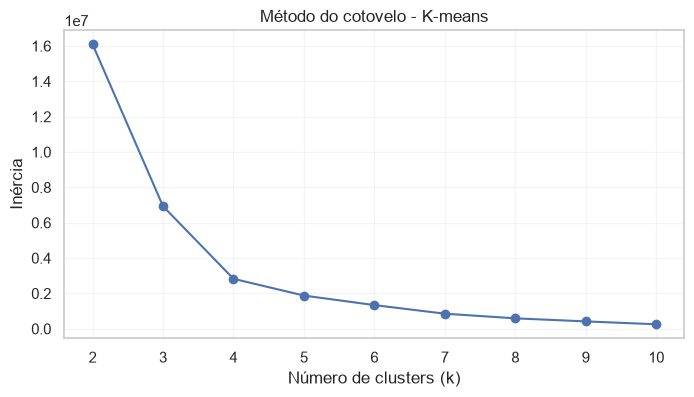

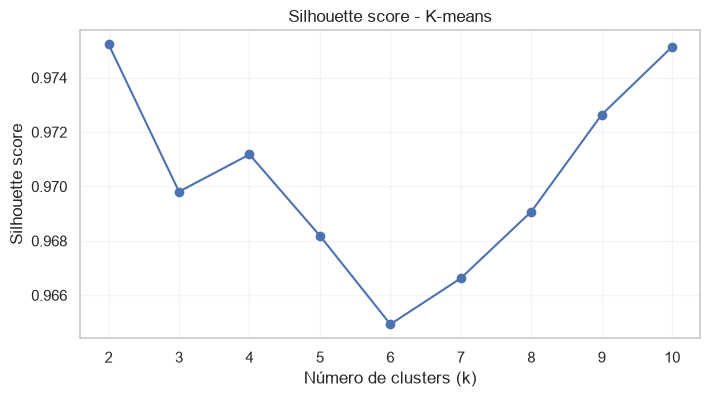

,k,Inércia,Silhouette
0,2,1.609561e+07,0.975229
1,3,6.932299e+06,0.969809
2,4,2.826750e+06,0.971177
3,5,1.878201e+06,0.968187
4,6,1.339397e+06,0.964933
5,7,8.530203e+05,0.966626
6,8,5.905973e+05,0.969076
7,9,4.165806e+05,0.972644
8,10,2.546153e+05,0.975140


In [491]:
# Escolha do número de clusters para K-means

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Curva do cotovelo
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")
plt.title("Método do cotovelo - K-means")
plt.grid(alpha=0.2)
plt.show()

# Silhouette
plt.figure(figsize=(8, 4))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score - K-means")
plt.grid(alpha=0.2)
plt.show()

# Valores numéricos
k_evaluation = pd.DataFrame({
    "k": list(k_values),
    "Inércia": inertias,
    "Silhouette": silhouette_scores
})

display(k_evaluation)

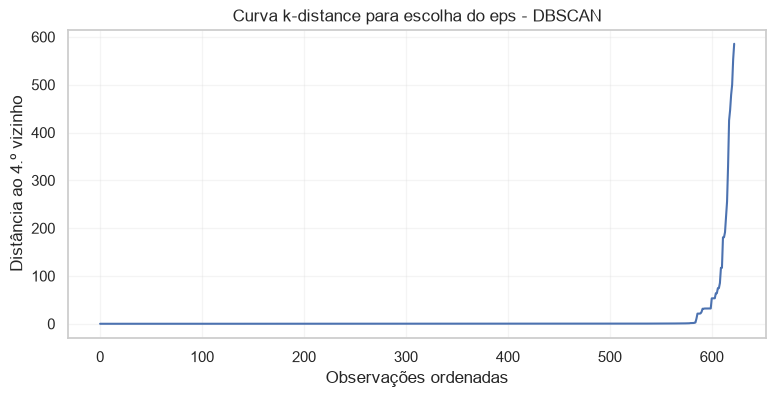

20 maiores distâncias ao 4.º vizinho:


,Distância
622,585.576352
621,553.192061
620,500.000226
619,478.723479
618,446.819249
617,425.533042
616,329.787817
615,255.319597
614,223.404402
613,191.491884


In [492]:
# Escolha do eps para DBSCAN através da distância ao 4.º vizinho

from sklearn.neighbors import NearestNeighbors

min_samples = 4

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

# Distância ao 4.º vizinho mais próximo
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.xlabel("Observações ordenadas")
plt.ylabel("Distância ao 4.º vizinho")
plt.title("Curva k-distance para escolha do eps - DBSCAN")
plt.grid(alpha=0.2)
plt.show()

# Mostrar as maiores distâncias para facilitar a escolha
print("20 maiores distâncias ao 4.º vizinho:")
display(
    pd.Series(k_distances)
    .sort_values(ascending=False)
    .head(20)
    .to_frame("Distância")
)

Quantis das distâncias ao 4.º vizinho:


0.50      0.106849
0.75      0.221121
0.90      0.559366
0.95     30.804218
0.97     56.933849
0.98    117.024618
0.99    313.404808
dtype: float64

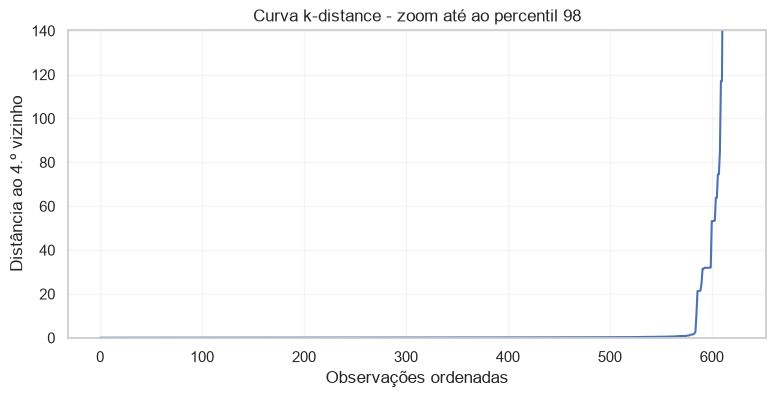

In [493]:
# Ampliar a região relevante da curva k-distance

print("Quantis das distâncias ao 4.º vizinho:")
display(
    pd.Series(k_distances).quantile(
        [0.50, 0.75, 0.90, 0.95, 0.97, 0.98, 0.99]
    )
)

# Zoom excluindo visualmente os extremos muito distantes
limit_98 = np.quantile(k_distances, 0.98)

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.ylim(0, limit_98 * 1.2)
plt.xlabel("Observações ordenadas")
plt.ylabel("Distância ao 4.º vizinho")
plt.title("Curva k-distance - zoom até ao percentil 98")
plt.grid(alpha=0.2)
plt.show()

,Percentil,Distância
0,0.900,0.559366
1,0.905,0.602648
2,0.910,0.722725
3,0.915,0.800162
4,0.920,0.823388
5,0.925,0.903224
6,0.930,1.228348
7,0.935,1.581662
8,0.940,8.289085
9,0.945,21.285754


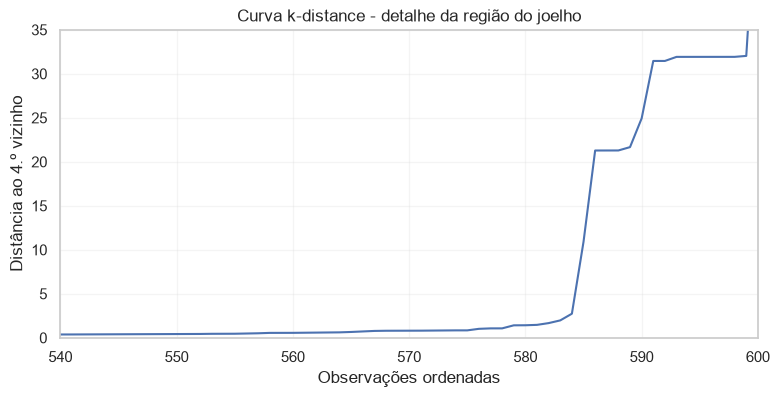

In [494]:
# Zoom detalhado na região do joelho da curva k-distance

quantiles_detail = np.arange(0.90, 0.951, 0.005)

detail = pd.DataFrame({
    "Percentil": quantiles_detail,
    "Distância": [
        np.quantile(k_distances, q)
        for q in quantiles_detail
    ]
})

display(detail)

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.xlim(540, 600)
plt.ylim(0, 35)
plt.xlabel("Observações ordenadas")
plt.ylabel("Distância ao 4.º vizinho")
plt.title("Curva k-distance - detalhe da região do joelho")
plt.grid(alpha=0.2)
plt.show()

In [495]:
# Aplicação de K-means e DBSCAN

from sklearn.cluster import KMeans, DBSCAN

# K-means com k escolhido pelo método do cotovelo
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# DBSCAN com parâmetros definidos pela curva k-distance
dbscan = DBSCAN(
    eps=2.0,
    min_samples=4
)

dbscan_labels = dbscan.fit_predict(X_scaled)

# Guardar resultados
multivariate_results = X.copy()
multivariate_results["KMeans_cluster"] = kmeans_labels
multivariate_results["DBSCAN_cluster"] = dbscan_labels

print("Tamanho dos clusters do K-means:")
display(
    multivariate_results["KMeans_cluster"]
    .value_counts()
    .sort_index()
)

print("\nTamanho dos clusters do DBSCAN:")
display(
    multivariate_results["DBSCAN_cluster"]
    .value_counts()
    .sort_index()
)

print("\nRegistos classificados como ruído pelo DBSCAN:")
print((dbscan_labels == -1).sum())

Tamanho dos clusters do K-means:


KMeans_cluster
0    586
1     23
2      9
3      5
Name: count, dtype: int64


Tamanho dos clusters do DBSCAN:


DBSCAN_cluster
-1     39
 0    550
 1     27
 2      7
Name: count, dtype: int64


Registos classificados como ruído pelo DBSCAN:
39


Candidatos sinalizados pelo K-means: 32
Candidatos sinalizados pelo DBSCAN: 39
Sinalizados pelos dois métodos: 27


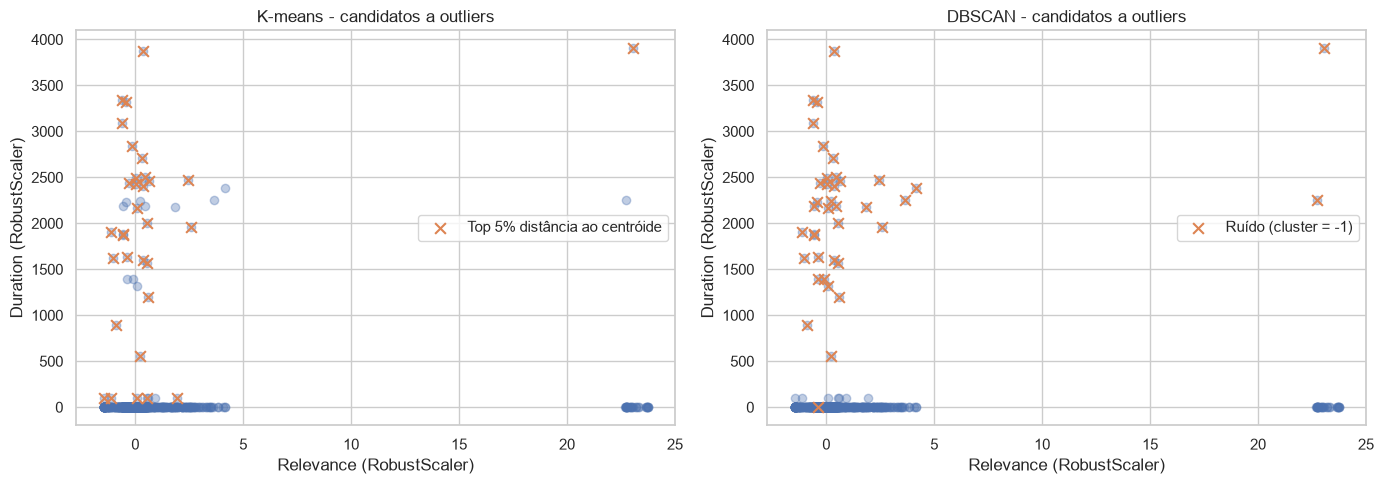

In [496]:
# Comparação visual entre K-means e DBSCAN

# Distância de cada registo ao centróide do seu cluster K-means
kmeans_distances = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[kmeans_labels],
    axis=1
)

# Top 5% das maiores distâncias como candidatos a outliers
kmeans_threshold = np.quantile(kmeans_distances, 0.95)
kmeans_outliers = kmeans_distances >= kmeans_threshold

# Ruído do DBSCAN
dbscan_outliers = dbscan_labels == -1

print("Candidatos sinalizados pelo K-means:",
      kmeans_outliers.sum())

print("Candidatos sinalizados pelo DBSCAN:",
      dbscan_outliers.sum())

print("Sinalizados pelos dois métodos:",
      (kmeans_outliers & dbscan_outliers).sum())

# Comparação lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-means
axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    alpha=0.35
)

axes[0].scatter(
    X_scaled[kmeans_outliers, 0],
    X_scaled[kmeans_outliers, 1],
    marker="x",
    s=60,
    label="Top 5% distância ao centróide"
)

axes[0].set_title("K-means - candidatos a outliers")
axes[0].set_xlabel("Relevance (RobustScaler)")
axes[0].set_ylabel("Duration (RobustScaler)")
axes[0].legend()

# DBSCAN
axes[1].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    alpha=0.35
)

axes[1].scatter(
    X_scaled[dbscan_outliers, 0],
    X_scaled[dbscan_outliers, 1],
    marker="x",
    s=60,
    label="Ruído (cluster = -1)"
)

axes[1].set_title("DBSCAN - candidatos a outliers")
axes[1].set_xlabel("Relevance (RobustScaler)")
axes[1].set_ylabel("Duration (RobustScaler)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [497]:
# Comparação dos registos sinalizados por K-means e DBSCAN

comparison = train.loc[X.index, [
    "Audio_Song",
    "Artist",
    "Title",
    "Relevance",
    "Duration"
]].copy()

comparison["KMeans_cluster"] = kmeans_labels
comparison["KMeans_distance"] = kmeans_distances
comparison["KMeans_outlier"] = kmeans_outliers

comparison["DBSCAN_cluster"] = dbscan_labels
comparison["DBSCAN_outlier"] = dbscan_outliers

# Encontrados apenas pelo K-means
only_kmeans = comparison[
    comparison["KMeans_outlier"] &
    ~comparison["DBSCAN_outlier"]
].sort_values("KMeans_distance", ascending=False)

# Encontrados apenas pelo DBSCAN
only_dbscan = comparison[
    ~comparison["KMeans_outlier"] &
    comparison["DBSCAN_outlier"]
].sort_values("KMeans_distance", ascending=False)

print("Sinalizados apenas pelo K-means:")
display(only_kmeans)

print("\nSinalizados apenas pelo DBSCAN:")
display(only_dbscan)

Sinalizados apenas pelo K-means:


,Audio_Song,Artist,Title,Relevance,Duration,KMeans_cluster,KMeans_distance,KMeans_outlier,DBSCAN_cluster,DBSCAN_outlier
382,MT0000811743,Buck Owens,My Last Chance With You,1.010870,9999.0,0,102.329669,True,2,False
788,MT0004550434,SNFU,Don't Have the Cow,1.016864,9999.0,0,102.322123,True,2,False
243,MT0014936205,The Drifters,There Goes My Baby,1.040531,9999.0,0,102.301387,True,2,False
317,MT0003669917,Third Day,Come Together,1.076848,9999.0,0,102.297683,True,2,False
525,MT0008794071,bing crosby,First Noel,1.049315,9999.0,0,102.297370,True,2,False



Sinalizados apenas pelo DBSCAN:


,Audio_Song,Artist,Title,Relevance,Duration,KMeans_cluster,KMeans_distance,KMeans_outlier,DBSCAN_cluster,DBSCAN_outlier
465,MT0008105399,Toby Keith,If I Was Jesus [Live],1.119855,224000.0,1,101.790007,False,-1,True
258,MT0026682960,Fats Domino,Your Cheatin' Heart,1.074180,205000.0,1,100.370269,False,-1,True
206,MT0001115644,Doug Stone,Gone Out of My Mind,1.027772,206000.0,1,89.757845,False,-1,True
640,MT0008966305,David Guetta,Sexy 17,1.047998,206000.0,1,89.738789,False,-1,True
849,MT0000197431,Connie Francis,Plenty Good Lovin',1.040357,124000.0,2,86.288671,False,-1,True
191,MT0012317309,BIG BILL BROONZY,Worrying My Mind,1.030536,210000.0,1,47.221890,False,-1,True
125,MT0034410340,John Lee Hooker,No Rollin' Blues,1.042727,211000.0,1,36.566916,False,-1,True
475,MT0027149420,jennifer lopez,Play,1.481410,212000.0,1,33.438260,False,-1,True
207,MT0001566152,Willie Nelson,Blue Hotel,1.110075,212000.0,1,25.984091,False,-1,True
528,MT0034549623,Jim Reeves,WHEN TWO WORLD COLLIDES,1.031309,131000.0,2,11.823089,False,-1,True


In [498]:
# Procurar registos encontrados pelo DBSCAN,
# mas não sinalizados por nenhum método univariado

def univariate_flags(series):
    x = series.dropna()

    # Z-score
    z = (x - x.mean()) / x.std(ddof=1)
    flag_z = np.abs(z) > 3

    # Modified Z-score (MAD)
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad

    if scaled_mad > 0:
        modified_z = (x - median) / scaled_mad
        flag_mad = np.abs(modified_z) > 3.5
    else:
        flag_mad = pd.Series(False, index=x.index)

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    flag_tukey = (
        (x < q1 - 1.5 * iqr) |
        (x > q3 + 1.5 * iqr)
    )

    return flag_z, flag_mad, flag_tukey


# Calcular flags para Relevance e Duration
flags = pd.DataFrame(index=X.index)

for col in ["Relevance", "Duration"]:
    z, mad, tukey = univariate_flags(train[col])

    flags.loc[z.index, f"{col}_Z"] = z
    flags.loc[mad.index, f"{col}_MAD"] = mad
    flags.loc[tukey.index, f"{col}_Tukey"] = tukey

flags = flags.fillna(False).astype(bool)

# Verdadeiro se qualquer método univariado sinalizou o registo
flags["Qualquer_univariado"] = flags.any(axis=1)

# Ruído DBSCAN que passou por todos os métodos univariados
candidate_444 = comparison.loc[
    dbscan_outliers & ~flags["Qualquer_univariado"]
].copy()

print("Ruídos do DBSCAN não detetados por nenhum método univariado:")
print(len(candidate_444))

display(candidate_444)

KeyError: '[4, 7, 14, 18, 29, 34, 35, 39, 44, 46, 49, 66, 73, 84, 90, 94, 100, 114, 116, 128, 129, 135, 136, 146, 148, 151, 161, 162, 164, 169, 188, 198, 212, 214, 219, 229, 231, 234, 235, 262, 269, 270, 274, 290, 297, 302, 307, 314, 320, 326, 336, 340, 354, 357, 369, 374, 375, 391, 396, 411, 423, 425, 426, 427, 470, 483, 492, 498, 499, 502, 503, 523, 527, 533, 542, 544, 560, 562, 568, 569, 572, 581, 583, 586, 587, 590, 591, 593, 596, 598, 601, 609, 621, 632, 634, 639, 649, 658, 661, 666, 674, 687, 692, 705, 717, 735, 738, 751, 760, 786, 789, 794, 795, 801, 804, 813, 814, 821, 824, 834, 844, 848, 851, 863, 865, 869, 879, 880, 884, 887, 889, 909, 910] not in index'

In [ ]:
# Procurar registos encontrados pelo DBSCAN,
# mas não sinalizados por nenhum método univariado

def univariate_flags(series):
    # Aqui os dados já pertencem ao mesmo conjunto X
    x = series.copy()

    # Z-score
    z = (x - x.mean()) / x.std(ddof=1)
    flag_z = np.abs(z) > 3

    # Modified Z-score (MAD)
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad

    if scaled_mad > 0:
        modified_z = (x - median) / scaled_mad
        flag_mad = np.abs(modified_z) > 3.5
    else:
        flag_mad = pd.Series(False, index=x.index)

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    flag_tukey = (
        (x < q1 - 1.5 * iqr) |
        (x > q3 + 1.5 * iqr)
    )

    return flag_z, flag_mad, flag_tukey


# DataFrame com exatamente os mesmos índices de X
flags = pd.DataFrame(index=X.index)

for col in ["Relevance", "Duration"]:
    z, mad, tukey = univariate_flags(X[col])

    flags[f"{col}_Z"] = z
    flags[f"{col}_MAD"] = mad
    flags[f"{col}_Tukey"] = tukey

# Foi sinalizado por pelo menos um método univariado?
flags["Qualquer_univariado"] = flags.any(axis=1)

# Converter o resultado do DBSCAN para Series com o mesmo índice
dbscan_outlier_series = pd.Series(
    dbscan_outliers,
    index=X.index
)

# DBSCAN encontrou, mas nenhum método univariado encontrou
candidate_444 = comparison.loc[
    dbscan_outlier_series & ~flags["Qualquer_univariado"]
].copy()

print("Ruídos do DBSCAN não detetados por nenhum método univariado:")
print(len(candidate_444))

display(candidate_444)

In [ ]:
# 4.4.4 - Procurar registos detetados pelo K-means,
# mas não detetados pelos métodos univariados

candidate_kmeans_444 = comparison.loc[
    comparison["KMeans_outlier"] & ~flags["Qualquer_univariado"]
].copy()

print("Outliers do K-means não detetados por nenhum método univariado:")
print(len(candidate_kmeans_444))

display(candidate_kmeans_444)

In [ ]:
from sklearn.cluster import DBSCAN

# Testar diferentes valores de eps próximos do joelho da curva k-distance
eps_values = [1.0, 1.5, 2.0, 3.0, 5.0, 10.0, 20.0]

resultados_eps = []

for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=4).fit_predict(X_scaled)

    ruido = labels == -1

    ruido_series = pd.Series(
        ruido,
        index=X.index
    )

    # Ruídos que NÃO foram encontrados pelos métodos univariados
    apenas_multivariado = ruido_series & ~flags["Qualquer_univariado"]

    resultados_eps.append({
        "eps": eps,
        "N_clusters": len(set(labels)) - (1 if -1 in labels else 0),
        "Ruídos": int(ruido.sum()),
        "Só multivariado": int(apenas_multivariado.sum())
    })

display(pd.DataFrame(resultados_eps))

In [ ]:
# Criar uma versão corrigida de Duration apenas para a análise multivariada

train_mv = train.copy()

def corrigir_duration(valor):
    if pd.isna(valor):
        return np.nan

    # Valores inválidos ou sentinelas
    if valor in [-1, 0, 9999]:
        return np.nan

    # Valores aparentemente armazenados em milissegundos
    if valor > 10000:
        return valor / 1000

    # Valores muito pequenos aparentemente armazenados em minutos
    if 0 < valor < 10:
        return valor * 60

    # Restantes já parecem estar em segundos
    return valor

train_mv["Duration_corrigida"] = train_mv["Duration"].apply(corrigir_duration)

print("Duration original:")
display(train["Duration"].describe())

print("\nDuration corrigida para análise:")
display(train_mv["Duration_corrigida"].describe())

In [ ]:
# Novo espaço multivariado com Duration corrigida

X_mv = train_mv[["Relevance", "Duration_corrigida"]].dropna().copy()

scaler_mv = RobustScaler()
X_mv_scaled = scaler_mv.fit_transform(X_mv)

print("Registos disponíveis:", len(X_mv))

print("\nResumo das variáveis:")
display(X_mv.describe().T)

In [ ]:
# Procurar anomalias exclusivamente multivariadas no espaço corrigido

from sklearn.cluster import DBSCAN

# DBSCAN no espaço corrigido
dbscan_mv = DBSCAN(eps=1.5, min_samples=4)
labels_mv = dbscan_mv.fit_predict(X_mv_scaled)

dbscan_noise_mv = pd.Series(
    labels_mv == -1,
    index=X_mv.index
)

# Criar flags univariadas no MESMO espaço corrigido
flags_mv = pd.DataFrame(index=X_mv.index)

for col in ["Relevance", "Duration_corrigida"]:
    x = X_mv[col]

    # Z-score
    z = np.abs((x - x.mean()) / x.std()) > 3

    # Modified Z / MAD
    mediana = x.median()
    mad = np.median(np.abs(x - mediana))
    mad_flag = np.abs((x - mediana) / (1.4826 * mad)) > 3.5

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    tukey = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)

    flags_mv[f"{col}_qualquer"] = z | mad_flag | tukey

flags_mv["Qualquer_univariado"] = flags_mv.any(axis=1)

# DBSCAN encontrou, mas nenhum método univariado encontrou
candidate_444_mv = X_mv.loc[
    dbscan_noise_mv & ~flags_mv["Qualquer_univariado"]
].copy()

print("Ruídos do DBSCAN:", int(dbscan_noise_mv.sum()))
print(
    "Ruídos não detetados por nenhum método univariado:",
    len(candidate_444_mv)
)

display(candidate_444_mv)

In [ ]:
print("Train atualmente utilizado:")
print(train.shape)

print("\nFicheiros CSV disponíveis nesta pasta e subpastas:")

import os

for root, dirs, files in os.walk("../../../.."):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

In [ ]:
# Verificar os datasets danificados originais, antes da limpeza

metadata_raw = pd.read_csv("merge_ecac/metadata.csv")
av_raw = pd.read_csv("merge_ecac/av_values.csv")
test_songs_raw = pd.read_csv("merge_ecac/test_songs.csv")

print("metadata.csv:", metadata_raw.shape)
print("av_values.csv:", av_raw.shape)
print("test_songs.csv:", test_songs_raw.shape)

print("\nColunas de metadata.csv:")
print(metadata_raw.columns.tolist())

print("\nColunas de av_values.csv:")
print(av_raw.columns.tolist())

print("\nColunas de test_songs.csv:")
print(test_songs_raw.columns.tolist())

In [ ]:
# Inspecionar Arousal e Valence antes da limpeza

print("Tipos das colunas:")
print(av_raw.dtypes)

print("\nResumo estatístico:")
display(av_raw[["Arousal", "Valence"]].describe().T)

print("\nValores ausentes:")
print(av_raw[["Arousal", "Valence"]].isna().sum())

# Identificar músicas pertencentes ao teste
test_ids = set(test_songs_raw["Audio_Song"])

av_train_raw = av_raw[
    ~av_raw["Audio_Song"].isin(test_ids)
].copy()

av_test_raw = av_raw[
    av_raw["Audio_Song"].isin(test_ids)
].copy()

print("\nAV treino:", av_train_raw.shape)
print("AV teste:", av_test_raw.shape)

In [ ]:
# Alinhar Arousal e Valence com o conjunto de treino já limpo

av_train = av_train_raw[
    av_train_raw["Audio_Song"].isin(train["Audio_Song"])
].copy()

# Verificar qual registo ficou de fora
av_removidos = av_train_raw[
    ~av_train_raw["Audio_Song"].isin(train["Audio_Song"])
]

print("AV treino original:", av_train_raw.shape)
print("AV treino após alinhamento:", av_train.shape)

print("\nRegisto presente no AV, mas já removido do train:")
display(av_removidos)

### 4.4.4 - Anomalia apenas multivariada

In [ ]:
flags_av = pd.DataFrame(index=av_train.index)

for col in ["Arousal", "Valence"]:
    x = av_train[col]

    # Z-score
    z = np.abs((x - x.mean()) / x.std(ddof=1)) > 3

    # Modified z-score baseado no MAD
    mediana = x.median()
    mad = np.median(np.abs(x - mediana))

    if mad > 0:
        mad_flag = np.abs(
            (x - mediana) / (1.4826 * mad)
        ) > 3.5
    else:
        mad_flag = pd.Series(False, index=x.index)

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    tukey = (
        (x < q1 - 1.5 * iqr) |
        (x > q3 + 1.5 * iqr)
    )

    flags_av[f"{col}_Z"] = z
    flags_av[f"{col}_MAD"] = mad_flag
    flags_av[f"{col}_Tukey"] = tukey

flags_av["Qualquer_univariado"] = flags_av.any(axis=1)

print("Outliers por critério:")
print(flags_av.sum())

print(
    "\nRegistos sem qualquer sinalização univariada:",
    (~flags_av["Qualquer_univariado"]).sum()
)

In [ ]:
# Curva k-distance para Arousal e Valence

from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import NearestNeighbors

# Espaço multivariado
X_av = av_train[["Arousal", "Valence"]].copy()

# Escalonamento robusto
scaler_av = RobustScaler()
X_av_scaled = scaler_av.fit_transform(X_av)

# min_samples = 4 -> distância ao 4.º vizinho
min_samples_av = 4

neighbors_av = NearestNeighbors(n_neighbors=min_samples_av)
neighbors_av.fit(X_av_scaled)

distances_av, _ = neighbors_av.kneighbors(X_av_scaled)

# Distância ao 4.º vizinho, ordenada
k_dist_av = np.sort(distances_av[:, -1])

# Mostrar percentis para ajudar na escolha do eps
percentis = [0.90, 0.92, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99]

print("Percentis da distância ao 4.º vizinho:")
for p in percentis:
    print(f"{p:.2f}: {np.quantile(k_dist_av, p):.4f}")

# Curva k-distance
plt.figure(figsize=(10, 5))
plt.plot(k_dist_av)
plt.xlabel("Observações ordenadas")
plt.ylabel("Distância ao 4.º vizinho")
plt.title("Curva k-distance - Arousal e Valence")
plt.grid(alpha=0.2)
plt.show()

In [ ]:
# Testar valores de eps na região do joelho

from sklearn.cluster import DBSCAN

resultados_eps_av = []

for eps in [0.10, 0.12, 0.14, 0.16, 0.18, 0.20]:
    
    dbscan = DBSCAN(
        eps=eps,
        min_samples=4
    )
    
    labels = dbscan.fit_predict(X_av_scaled)
    ruido = labels == -1
    
    # Converter para Series com o mesmo índice
    ruido_series = pd.Series(
        ruido,
        index=X_av.index
    )
    
    apenas_multivariado = (
        ruido_series &
        ~flags_av["Qualquer_univariado"]
    )
    
    resultados_eps_av.append({
        "eps": eps,
        "N_clusters": len(set(labels)) - (1 if -1 in labels else 0),
        "Ruídos": int(ruido.sum()),
        "Só_multivariado": int(apenas_multivariado.sum())
    })

resultados_eps_av = pd.DataFrame(resultados_eps_av)

display(resultados_eps_av)

In [ ]:
# Identificar registos encontrados apenas pela análise multivariada

# Índices dos candidatos dentro de av_train
candidate_indices = only_multivariate[only_multivariate].index

# Obter Arousal, Valence e Audio_Song
candidatos_av = av_train.loc[
    candidate_indices,
    ["Audio_Song", "Arousal", "Valence"]
].copy()

# Juntar com os metadados usando Audio_Song como identificador
candidatos_444 = candidatos_av.merge(
    train[["Audio_Song", "Artist", "Title", "Quadrant"]],
    on="Audio_Song",
    how="left"
)

# Organizar as colunas
candidatos_444 = candidatos_444[
    ["Audio_Song", "Artist", "Title",
     "Quadrant", "Arousal", "Valence"]
]

print("Número de candidatos ao 4.4.4:", len(candidatos_444))

display(
    candidatos_444.sort_values(
        ["Arousal", "Valence"]
    )
)

In [ ]:
# 4.4.4 - Encontrar o candidato menos extremo individualmente

analise_444 = candidatos_444.copy()

# Percentil de cada valor dentro da distribuição completa
analise_444["Percentil_Arousal"] = analise_444["Arousal"].apply(
    lambda x: (av_train["Arousal"] <= x).mean()
)

analise_444["Percentil_Valence"] = analise_444["Valence"].apply(
    lambda x: (av_train["Valence"] <= x).mean()
)

# Distância de cada percentil ao centro da distribuição (0.5)
analise_444["Extremo_univariado"] = (
    abs(analise_444["Percentil_Arousal"] - 0.5) +
    abs(analise_444["Percentil_Valence"] - 0.5)
)

# Menor valor = menos extremo individualmente
analise_444 = analise_444.sort_values("Extremo_univariado")

display(
    analise_444[
        [
            "Audio_Song",
            "Artist",
            "Title",
            "Arousal",
            "Valence",
            "Percentil_Arousal",
            "Percentil_Valence",
            "Extremo_univariado"
        ]
    ]
)

In [ ]:
# Visualização do registo isolado

# Registo escolhido
registro_444 = candidatos_444[
    candidatos_444["Audio_Song"] == "MT0031893087"
].iloc[0]

plt.figure(figsize=(9, 6))

# Todos os registos
plt.scatter(
    av_train["Arousal"],
    av_train["Valence"],
    alpha=0.35,
    label="Registos normais"
)

# Ruídos encontrados pelo DBSCAN
ruidos_av = av_train.loc[dbscan_noise_av]

plt.scatter(
    ruidos_av["Arousal"],
    ruidos_av["Valence"],
    marker="x",
    s=70,
    label="Ruído DBSCAN"
)

# Destacar Let Love Rule
plt.scatter(
    registro_444["Arousal"],
    registro_444["Valence"],
    marker="*",
    s=250,
    label="Let Love Rule"
)

plt.annotate(
    "Let Love Rule",
    (registro_444["Arousal"], registro_444["Valence"]),
    xytext=(10, 10),
    textcoords="offset points"
)

plt.xlabel("Arousal")
plt.ylabel("Valence")
plt.title("Anomalia multivariada não detetada univariadamente")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

O registo correspondente à música *Let Love Rule*, de Lenny Kravitz, constitui um exemplo de uma observação que não é particularmente extrema em nenhuma variável considerada isoladamente, mas que apresenta um comportamento invulgar na distribuição conjunta.

O seu Arousal é 0.465 (aproximadamente percentil 43) e a sua Valence é 0.579 (aproximadamente percentil 53). Assim, nenhum dos métodos univariados utilizados (z-score, modified z-score baseado no MAD e Tukey's fences) sinalizou este registo como outlier.

No entanto, o DBSCAN classificou-o como ruído devido à baixa densidade de observações na sua vizinhança no espaço conjunto Arousal-Valence. Isto demonstra que uma observação pode não ser extrema em nenhuma dimensão individual e, ainda assim, ser anómala devido à combinação das suas características.

Neste caso, o método multivariado conseguiu identificar uma estrutura que os métodos univariados não conseguem observar.

### 4.4.5 - Extremos legítimos

In [ ]:
# Inspecionar os extremos univariados de Arousal e Valence

extremos_univariados = av_train.loc[
    flags_av["Qualquer_univariado"],
    ["Audio_Song", "Lyric_Song", "Arousal", "Valence"]
].copy()

# Adicionar informação da música
extremos_univariados = extremos_univariados.merge(
    train[["Audio_Song", "Artist", "Title", "Quadrant"]],
    on="Audio_Song",
    how="left"
)

# Verificar se os valores continuam dentro do domínio válido [0, 1]
extremos_univariados["Arousal_valido"] = extremos_univariados["Arousal"].between(0, 1)
extremos_univariados["Valence_valido"] = extremos_univariados["Valence"].between(0, 1)

print("Registos sinalizados pelos métodos univariados:")
display(extremos_univariados)

In [ ]:
# Confirmar se o valor extremo existe no dataset original

av_original = pd.read_csv("merge_original/av_values.csv")

happy_original = av_original.loc[
    (av_original["Audio_Song"] == "A095-113") |
    (av_original["Lyric_Song"] == "L145-113")
]

print("Registo correspondente no dataset original:")
display(happy_original)

Nem todos os registos sinalizados como outliers correspondem a erros e, por isso, a sinalização estatística não foi utilizada diretamente como critério de remoção.

Um exemplo é a música *Happy*, de Pharrell Williams, que apresenta Arousal = 0.975 e Valence = 0.9875. O registo foi sinalizado pelos métodos univariados devido ao valor extremo de Arousal. No entanto, ambos os valores permanecem dentro do domínio válido [0, 1] e os mesmos valores foram encontrados no conjunto de dados original (`merge_original/av_values.csv`).

Assim, este registo constitui um extremo legítimo e deve ser preservado. O critério de limpeza distingue a deteção estatística da decisão de remoção: um registo sinalizado apenas por ser extremo não é eliminado quando respeita o domínio da variável e é consistente com os dados originais. Desta forma, evita-se remover observações raras, mas válidas, que representam informação real da distribuição.

### 4.4.6 - Erros e outliers

In [ ]:
# erro que também é detetado como outlier

duration_extremos = train.loc[
    train["Duration"].notna(),
    ["Audio_Song", "Artist", "Title", "Quadrant", "Duration"]
].copy()

# Mostrar os menores e maiores valores de Duration
print("Menores valores de Duration:")
display(duration_extremos.nsmallest(10, "Duration"))

print("\nMaiores valores de Duration:")
display(duration_extremos.nlargest(10, "Duration"))

In [ ]:
# 4.4.6 - Caso 1: verificar o maior Duration no dataset original

metadata_original = pd.read_csv("merge_original/metadata.csv")

summer_days_original = metadata_original.loc[
    metadata_original["Audio_Song"] == "MT0031834881",
    ["Audio_Song", "Artist", "Title", "Duration"]
]

summer_days_ecac = train.loc[
    train["Audio_Song"] == "MT0031834881",
    ["Audio_Song", "Artist", "Title", "Duration"]
]

print("Dataset danificado:")
display(summer_days_ecac)

print("\nDataset original:")
display(summer_days_original)

In [ ]:
# 4.4.6 - Caso 2:
# procurar inconsistências detetáveis por relações entre duas colunas

print("Exemplos de Year, LowestYear e ActualYear:")
display(
    train[
        ["Audio_Song", "Artist", "Title", "Year", "LowestYear", "ActualYear"]
    ].head(20)
)

print("\nTipos das três variáveis:")
print(
    train[
        ["Year", "LowestYear", "ActualYear"]
    ].dtypes
)

print("\nValores únicos de exemplo:")
for col in ["Year", "LowestYear", "ActualYear"]:
    print(f"\n{col}:")
    print(train[col].dropna().astype(str).unique()[:30])

In [ ]:
# 4.4.6 - Caso 2:
# verificar inconsistências entre Year e ActualYear

year_check = train[
    ["Audio_Song", "Artist", "Title", "Year", "ActualYear"]
].copy()

# Extrair um ano de 4 dígitos da coluna Year
year_check["Year_extraido"] = pd.to_numeric(
    year_check["Year"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

# Converter ActualYear para número
year_check["ActualYear_num"] = pd.to_numeric(
    year_check["ActualYear"],
    errors="coerce"
)

# Selecionar casos em que os dois anos existem, mas discordam
year_inconsistentes = year_check.loc[
    year_check["Year_extraido"].notna()
    & year_check["ActualYear_num"].notna()
    & (year_check["Year_extraido"] != year_check["ActualYear_num"])
].copy()

print("Número de inconsistências Year x ActualYear:")
print(len(year_inconsistentes))

display(year_inconsistentes.head(30))

In [ ]:
# 4.4.6 - Caso 2:
# erro detetado por uma regra entre duas colunas
# LowestYear nunca deve ser posterior a ActualYear

year_rule = train[
    ["Audio_Song", "Artist", "Title", "LowestYear", "ActualYear"]
].copy()

# Extrair o ano de LowestYear
year_rule["LowestYear_num"] = pd.to_numeric(
    year_rule["LowestYear"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

# Converter ActualYear para número
year_rule["ActualYear_num"] = pd.to_numeric(
    year_rule["ActualYear"],
    errors="coerce"
)

# Manter apenas anos plausíveis para este teste
year_rule_validos = year_rule.loc[
    year_rule["LowestYear_num"].between(1900, 2026)
    & year_rule["ActualYear_num"].between(1900, 2026)
].copy()

# Regra do Data Dictionary:
# LowestYear não pode ser posterior a ActualYear
violacoes_year = year_rule_validos.loc[
    year_rule_validos["LowestYear_num"] >
    year_rule_validos["ActualYear_num"]
].copy()

print("Violações da regra LowestYear <= ActualYear:")
print(len(violacoes_year))

display(
    violacoes_year.sort_values(
        ["LowestYear_num", "ActualYear_num"]
    )
)

In [ ]:
# 4.4.6 - Confirmar no dataset original a violação entre duas colunas

metadata_original = pd.read_csv("merge_original/metadata.csv")

audio_caso = "MT0001741017"

print("Dataset danificado:")
display(
    train.loc[
        train["Audio_Song"] == audio_caso,
        ["Audio_Song", "Artist", "Title", "LowestYear", "ActualYear"]
    ]
)

print("\nDataset original:")
display(
    metadata_original.loc[
        metadata_original["Audio_Song"] == audio_caso,
        ["Audio_Song", "Artist", "Title", "LowestYear", "ActualYear"]
    ]
)

In [ ]:
# 4.4.6 - Caso 3:
# verificar se a anomalia multivariada "Let Love Rule"
# corresponde a uma corrupção introduzida no dataset

audio_caso_mv = "MT0031893087"

print("Dataset danificado:")
display(
    av_train.loc[
        av_train["Audio_Song"] == audio_caso_mv,
        ["Audio_Song", "Lyric_Song", "Arousal", "Valence"]
    ]
)

print("\nDataset original:")
display(
    av_original.loc[
        av_original["Audio_Song"] == audio_caso_mv,
        ["Audio_Song", "Lyric_Song", "Arousal", "Valence"]
    ]
)

In [ ]:
# 4.4.6 - Procurar, entre as anomalias multivariadas,
# quais foram realmente alteradas no dataset danificado

comparacao_mv = candidatos_444[
    ["Audio_Song", "Artist", "Title", "Quadrant", "Arousal", "Valence"]
].merge(
    av_original[
        ["Audio_Song", "Arousal", "Valence"]
    ],
    on="Audio_Song",
    how="left",
    suffixes=("_danificado", "_original")
)

# Verificar alterações
comparacao_mv["Arousal_alterado"] = (
    comparacao_mv["Arousal_danificado"] !=
    comparacao_mv["Arousal_original"]
)

comparacao_mv["Valence_alterado"] = (
    comparacao_mv["Valence_danificado"] !=
    comparacao_mv["Valence_original"]
)

comparacao_mv["Foi_alterado"] = (
    comparacao_mv["Arousal_alterado"] |
    comparacao_mv["Valence_alterado"]
)

print("Candidatos multivariados:", len(comparacao_mv))
print(
    "Candidatos com Arousal ou Valence diferentes do original:",
    comparacao_mv["Foi_alterado"].sum()
)

display(
    comparacao_mv.sort_values(
        "Foi_alterado",
        ascending=False
    )
)

In [ ]:
# 4.4.6 - Procurar alterações numéricas plausíveis no metadata
# para encontrar um erro que só se destaque multivariadamente

metadata_original = pd.read_csv("merge_original/metadata.csv")

# Juntar dataset danificado e original pelo identificador da música
comparacao_metadata = train.merge(
    metadata_original,
    on="Audio_Song",
    how="inner",
    suffixes=("_danificado", "_original")
)

colunas_numericas_comparar = [
    "Relevance",
    "Duration",
    "Sample",
    "num_Genres",
    "num_MoodsAll"
]

resultados_alteracoes = []

for col in colunas_numericas_comparar:
    col_d = f"{col}_danificado"
    col_o = f"{col}_original"

    if col_d not in comparacao_metadata.columns or col_o not in comparacao_metadata.columns:
        continue

    d = pd.to_numeric(comparacao_metadata[col_d], errors="coerce")
    o = pd.to_numeric(comparacao_metadata[col_o], errors="coerce")

    alterado = (
        d.notna() &
        o.notna() &
        ~np.isclose(d, o, equal_nan=True)
    )

    temp = comparacao_metadata.loc[
        alterado,
        ["Audio_Song", "Artist_danificado", "Title_danificado"]
    ].copy()

    temp["Variavel"] = col
    temp["Valor_danificado"] = d[alterado].values
    temp["Valor_original"] = o[alterado].values

    resultados_alteracoes.append(temp)

alteracoes_numericas = pd.concat(
    resultados_alteracoes,
    ignore_index=True
)

print("Número de alterações numéricas encontradas:")
print(len(alteracoes_numericas))

print("\nAlterações por variável:")
display(
    alteracoes_numericas["Variavel"]
    .value_counts()
    .rename_axis("Variavel")
    .reset_index(name="N_alteracoes")
)

print("\nAlterações encontradas:")
display(alteracoes_numericas)

In [ ]:
# 4.4.6 - Investigar a alteração subtil de Relevance

audio_michael = "MT0002604697"

# Localizar o registo no train
idx_michael = train.index[
    train["Audio_Song"] == audio_michael
]

print("Índice no train:", idx_michael.tolist())

print("\nRegisto de Michael Franks:")
display(
    train.loc[
        idx_michael,
        ["Audio_Song", "Artist", "Title", "Relevance", "Duration"]
    ]
)

# Verificar os três critérios univariados para Relevance
x = train["Relevance"].dropna()

media = x.mean()
desvio = x.std(ddof=1)
mediana = x.median()
mad = np.median(np.abs(x - mediana))

q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1

valor = train.loc[idx_michael[0], "Relevance"]

z = abs((valor - media) / desvio)
modified_z = abs((valor - mediana) / (1.4826 * mad))
tukey = (valor < q1 - 1.5 * iqr) or (valor > q3 + 1.5 * iqr)

print("\nRelevance danificado:", valor)
print("Z-score:", round(z, 4), "-> outlier:", z > 3)
print("Modified Z:", round(modified_z, 4), "-> outlier:", modified_z > 3.5)
print("Tukey -> outlier:", tukey)

# Verificar se o DBSCAN anterior em Relevance + Duration_corrigida o sinalizou
dbscan_series_mv = pd.Series(
    dbscan_noise_mv,
    index=X_mv.index
)

print(
    "\nDBSCAN Relevance + Duration_corrigida -> outlier:",
    bool(dbscan_series_mv.reindex(idx_michael, fill_value=False).iloc[0])
)

In [ ]:
# 4.4.6 - Mapear as alterações conhecidas no truth_cells

truth_cells = pd.read_csv("truth/truth_cells.csv")

print("Dimensões:", truth_cells.shape)

print("\nColunas:")
print(truth_cells.columns.tolist())

print("\nPrimeiras alterações:")
display(truth_cells.head(15))

print("\nTipos de alterações / colunas afetadas:")

# Encontrar automaticamente a coluna que identifica
# qual variável do dataset foi modificada
for col in truth_cells.columns:
    print(f"\n{col}:")
    print(truth_cells[col].value_counts(dropna=False).head(20))

In [ ]:
# Resumo compacto das corrupções registadas no truth_cells

print("Colunas do truth_cells:")
print(truth_cells.columns.tolist())

print("\nNúmero de alterações por variável:")
display(
    truth_cells["column"]
    .value_counts()
    .rename_axis("Variável")
    .reset_index(name="N_alterações")
)

In [ ]:
# 4.4.6 - Procurar corrupção de Relevance detetada apenas multivariadamente

# IDs cuja Relevance foi deliberadamente alterada
truth_relevance = truth_cells.loc[
    truth_cells["column"] == "Relevance",
    ["song_id", "original_value", "corrupted_value"]
].copy()

# DBSCAN anterior, alinhado pelos índices usados em X_mv
dbscan_flag = pd.Series(
    dbscan_noise_mv,
    index=X_mv.index,
    name="DBSCAN"
)

# Flags univariadas de Relevance no train
relevance_flags = pd.DataFrame(index=train.index)

x = train["Relevance"]

media = x.mean()
desvio = x.std()
relevance_flags["Z"] = np.abs((x - media) / desvio) > 3

mediana = x.median()
mad = np.median(np.abs(x.dropna() - mediana))
relevance_flags["MAD"] = (
    np.abs((x - mediana) / (1.4826 * mad)) > 3.5
)

q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1
relevance_flags["Tukey"] = (
    (x < q1 - 1.5 * iqr) |
    (x > q3 + 1.5 * iqr)
)

relevance_flags["Univariado"] = relevance_flags.any(axis=1)

# Juntar as corrupções conhecidas com o conjunto de treino
candidatos_rel = train[
    ["Audio_Song", "Artist", "Title", "Relevance"]
].copy()

candidatos_rel["DBSCAN"] = dbscan_flag.reindex(
    candidatos_rel.index,
    fill_value=False
)

candidatos_rel["Univariado"] = relevance_flags["Univariado"]

candidatos_rel = candidatos_rel.merge(
    truth_relevance,
    left_on="Audio_Song",
    right_on="song_id",
    how="inner"
)

# Queremos:
# corrupção real + DBSCAN deteta + nenhum método univariado deteta
caso_joint = candidatos_rel.loc[
    candidatos_rel["DBSCAN"] &
    ~candidatos_rel["Univariado"]
].copy()

print(
    "Corrupções de Relevance detetadas pelo DBSCAN "
    "mas não univariadamente:",
    len(caso_joint)
)

display(caso_joint)

In [ ]:
# 4.4.6 - Investigar os tipos de defeitos introduzidos

print("Defeitos por tipo:")
display(
    truth_cells["defect_code"]
    .value_counts(dropna=False)
    .rename_axis("Defeito")
    .reset_index(name="N")
)

print("\nDefeitos por variável:")
display(
    truth_cells.groupby(
        ["column", "defect_code"],
        dropna=False
    )
    .size()
    .reset_index(name="N")
    .sort_values(["column", "N"], ascending=[True, False])
)

In [ ]:
# 4.4.6 - Inspecionar os cinco casos especiais H1-H5

casos_H = truth_cells.loc[
    truth_cells["defect_code"].isin(["H1", "H2", "H3", "H4", "H5"]),
    [
        "song_id",
        "column",
        "original_value",
        "corrupted_value",
        "defect_code"
    ]
].copy()

# Acrescentar informação da música quando ela estiver no treino
casos_H = casos_H.merge(
    train[["Audio_Song", "Artist", "Title", "Quadrant"]],
    left_on="song_id",
    right_on="Audio_Song",
    how="left"
)

display(
    casos_H[
        [
            "defect_code",
            "song_id",
            "Artist",
            "Title",
            "Quadrant",
            "column",
            "original_value",
            "corrupted_value"
        ]
    ].sort_values("defect_code")
)

In [ ]:
# 4.4.6 - Investigar alterações realizadas ao nível do registo

truth_rows = pd.read_csv("truth/truth_rows.csv")

print("Dimensões:", truth_rows.shape)

print("\nColunas:")
print(truth_rows.columns.tolist())

print("\nPrimeiros registos:")
display(truth_rows.head(20))

# Mostrar distribuição das colunas categóricas
print("\nValores existentes em cada coluna:")
for col in truth_rows.columns:
    print(f"\n{col}:")
    print(truth_rows[col].value_counts(dropna=False).head(20))

In [ ]:
# Resumo compacto das alterações ao nível dos registos

print("Número de registos no truth_rows:", len(truth_rows))

print("\nAções:")
display(
    truth_rows["action"]
    .value_counts(dropna=False)
    .rename_axis("Ação")
    .reset_index(name="N")
)

print("\nDefeitos:")
display(
    truth_rows["defect_code"]
    .value_counts(dropna=False)
    .rename_axis("Defeito")
    .reset_index(name="N")
)

print("\nCombinação entre ação e defeito:")
display(
    truth_rows.groupby(
        ["action", "defect_code"],
        dropna=False
    )
    .size()
    .reset_index(name="N")
)

In [ ]:
# 4.4.6 - Verificar as variáveis disponíveis para o caso H1

audio_h1 = "MT0002604697"

linha_h1 = train.loc[
    train["Audio_Song"] == audio_h1
].copy()

print("Registo H1 completo:")
display(linha_h1.T)

print("\nVariáveis numéricas disponíveis no H1:")
for col in train.select_dtypes(include=np.number).columns:
    print(f"{col}: {linha_h1[col].iloc[0]}")

In [ ]:
# 4.4.6 - Inspecionar conjuntamente os defeitos especiais H1-H5

hidden = truth_cells[
    truth_cells["defect_code"].isin(["H1", "H2", "H3", "H4", "H5"])
].copy()

# Informações disponíveis no conjunto de treino
cols_train = [
    "Audio_Song", "Artist", "Title", "Quadrant",
    "Relevance", "Duration", "Year", "LowestYear", "ActualYear"
]

train_info = train[cols_train].copy()

hidden_info = hidden.merge(
    train_info,
    left_on="song_id",
    right_on="Audio_Song",
    how="left"
)

hidden_info["Presente_no_train"] = hidden_info["Audio_Song"].notna()

display(
    hidden_info[
        [
            "defect_code",
            "song_id",
            "Presente_no_train",
            "column",
            "original_value",
            "corrupted_value",
            "Artist",
            "Title",
            "Quadrant",
            "Relevance",
            "Duration",
            "Year",
            "LowestYear",
            "ActualYear"
        ]
    ].sort_values("defect_code")
)

In [ ]:
# 4.4.6 - Verificar H2 e H5 através das relações entre anos

casos_anos = ["MT0033459750", "A107-115"]

verificacao_anos = train.loc[
    train["Audio_Song"].isin(casos_anos),
    [
        "Audio_Song",
        "Artist",
        "Title",
        "Year",
        "LowestYear",
        "ActualYear"
    ]
].copy()

# Extrair um ano numérico de Year e LowestYear
verificacao_anos["Year_num"] = pd.to_numeric(
    verificacao_anos["Year"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

verificacao_anos["LowestYear_num"] = pd.to_numeric(
    verificacao_anos["LowestYear"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

verificacao_anos["ActualYear_num"] = pd.to_numeric(
    verificacao_anos["ActualYear"],
    errors="coerce"
)

# Relações que esperamos que sejam coerentes
verificacao_anos["LowestYear_maior_ActualYear"] = (
    verificacao_anos["LowestYear_num"] >
    verificacao_anos["ActualYear_num"]
)

verificacao_anos["Year_diferente_ActualYear"] = (
    verificacao_anos["Year_num"] !=
    verificacao_anos["ActualYear_num"]
)

display(verificacao_anos)

In [ ]:
# 4.4.6 - Investigar H2 na distribuição conjunta LowestYear x ActualYear

anos_joint = train[
    ["Audio_Song", "Artist", "Title", "LowestYear", "ActualYear"]
].copy()

anos_joint["LowestYear_num"] = pd.to_numeric(
    anos_joint["LowestYear"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

anos_joint["ActualYear_num"] = pd.to_numeric(
    anos_joint["ActualYear"],
    errors="coerce"
)

# Apenas registos em que os dois anos estão disponíveis
anos_joint = anos_joint.dropna(
    subset=["LowestYear_num", "ActualYear_num"]
).copy()

# Diferença entre as duas variáveis
anos_joint["Diferenca"] = (
    anos_joint["ActualYear_num"] -
    anos_joint["LowestYear_num"]
)

print("Distribuição da diferença ActualYear - LowestYear:")
display(anos_joint["Diferenca"].describe())

print("\nFrequências das diferenças:")
display(
    anos_joint["Diferenca"]
    .value_counts()
    .sort_index()
    .head(30)
)

print("\nH2 na distribuição conjunta:")
display(
    anos_joint.loc[
        anos_joint["Audio_Song"] == "MT0033459750"
    ]
)

print("\nMaiores diferenças encontradas:")
display(
    anos_joint.sort_values(
        "Diferenca",
        ascending=False
    ).head(20)
)

A análise realizada confirma que um outlier estatístico não é necessariamente um erro e, inversamente, que alguns erros podem não apresentar valores extremos quando as variáveis são consideradas isoladamente.

**1. Erro que também é um outlier**

O registo *I Gotta Right to Sing the Blues*, de Ella Fitzgerald (`MT0004184616`), constitui um exemplo claro. O valor de `Relevance` foi alterado de aproximadamente 1.041 para 1.84. O valor corrompido é estatisticamente extremo e corresponde efetivamente a uma alteração artificial do conjunto de dados. Neste caso, a deteção de outlier coincide com um erro real.

**2. Erro não detetado univariadamente, mas identificado por uma regra entre duas colunas**

A música *Find out What's Happening*, de Elvis Presley (`MT0001741017`), apresenta `LowestYear = 1973` e `ActualYear = 1972` no conjunto danificado. Individualmente, ambos são anos perfeitamente plausíveis. Contudo, a relação `LowestYear <= ActualYear` é violada. No conjunto original, `ActualYear = 1973`. Assim, uma regra envolvendo duas variáveis identifica um erro que não depende de qualquer valor individualmente extremo.

**3. Erro revelado pela distribuição conjunta**

No registo *Epistle to Derroll*, de Donovan (`MT0033459750`), `LowestYear` foi alterado de 1967 para 1962, enquanto `ActualYear` permanece 1967. Nenhum dos dois valores é individualmente implausível e a regra `LowestYear <= ActualYear` continua satisfeita. Contudo, a distribuição conjunta mostra que `ActualYear` e `LowestYear` coincidem na grande maioria dos registos: os percentis 25%, 50% e 75% da diferença `ActualYear - LowestYear` são todos iguais a zero. A alteração introduz uma combinação incomum que não é revelada pela inspeção isolada das variáveis nem pela regra simples utilizada anteriormente.

**4. Outlier que não é um erro**

A música *Happy*, de Pharrell Williams (`A095-113`), apresenta `Arousal = 0.975` e `Valence = 0.9875`, sendo sinalizada devido à sua posição extrema na distribuição. No entanto, os mesmos valores encontram-se no conjunto de dados original e pertencem ao domínio válido das variáveis. Trata-se, portanto, de um extremo legítimo que deve ser preservado.

Estes exemplos mostram por que motivo a sinalização de uma observação como outlier não deve implicar automaticamente a sua remoção. A decisão deve considerar o domínio das variáveis, relações entre atributos, distribuição conjunta e, quando disponível, evidência proveniente dos dados originais.

## 4.5 - Inspeção inicial dos ficheiros multimédia

### 4.5.1 Inspeção das capas e dos ficheiros de áudio


In [ ]:
from pathlib import Path
from collections import Counter

media_root = Path("../../dataset")

print("Pasta encontrada:", media_root.exists())
print("Caminho:", media_root.resolve())

# Todos os ficheiros existentes
files = [p for p in media_root.rglob("*") if p.is_file()]

print("\nTotal de ficheiros:", len(files))

# Extensões
extensoes = Counter(p.suffix.lower() for p in files)

print("\nExtensões encontradas:")
for ext, n in extensoes.most_common():
    print(f"{ext or '[sem extensão]'}: {n}")

# Estrutura das primeiras pastas
print("\nPastas principais:")
for p in sorted(media_root.iterdir()):
    print(p.name)

# Exemplos de imagens e áudios
image_ext = {".jpg", ".jpeg", ".png"}
audio_ext = {".mp3", ".wav", ".flac", ".m4a"}

images = [p for p in files if p.suffix.lower() in image_ext]
audios = [p for p in files if p.suffix.lower() in audio_ext]

print("\nImagens:", len(images))
print("Áudios:", len(audios))

print("\nExemplos de imagens:")
for p in images[:5]:
    print(p)

print("\nExemplos de áudios:")
for p in audios[:5]:
    print(p)

In [ ]:
# 4.5.1 - Inspeção das capas dos álbuns

from PIL import Image
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

# IDs dos ficheiros
audio_ids = {p.stem for p in audios}
cover_ids = {p.stem for p in images}

# Capas em falta
missing_covers = sorted(audio_ids - cover_ids)

print("Músicas com áudio:", len(audio_ids))
print("Músicas com capa:", len(cover_ids))
print("Áudios sem capa:", len(missing_covers))

print("\nExemplos de áudios sem capa:")
print(missing_covers[:20])

# Dimensões e hash das imagens
cover_info = []

for p in images:
    try:
        with Image.open(p) as img:
            width, height = img.size

        with open(p, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        cover_info.append({
            "id": p.stem,
            "width": width,
            "height": height,
            "hash": file_hash
        })

    except Exception as e:
        print("Erro ao ler:", p, e)

cover_df = pd.DataFrame(cover_info)

# Imagens exatamente repetidas
duplicate_hashes = (
    cover_df.groupby("hash")
    .size()
    .sort_values(ascending=False)
)

duplicate_hashes = duplicate_hashes[duplicate_hashes > 1]

print("\nCapas analisadas:", len(cover_df))
print("Grupos de imagens exatamente repetidas:", len(duplicate_hashes))
print(
    "Ficheiros pertencentes a grupos repetidos:",
    duplicate_hashes.sum()
)

print("\nDimensões mais frequentes:")
display(
    cover_df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

# Gráfico pedido no enunciado
plt.figure(figsize=(7,5))
plt.scatter(
    cover_df["width"],
    cover_df["height"],
    alpha=0.5
)

plt.xlabel("Largura (px)")
plt.ylabel("Altura (px)")
plt.title("Dimensões das capas dos álbuns")
plt.grid(alpha=0.2)
plt.show()

In [ ]:
# 4.5.1 - Inspeção dos ficheiros de áudio sem bibliotecas adicionais

import hashlib
import pandas as pd
import matplotlib.pyplot as plt

audio_info = []

for p in audios:
    try:
        with open(p, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        audio_info.append({
            "id": p.stem,
            "size_mb": p.stat().st_size / (1024**2),
            "hash": file_hash
        })

    except Exception:
        pass

audio_df = pd.DataFrame(audio_info)

print("Áudios analisados:", len(audio_df))

print("\nEstatísticas do tamanho dos ficheiros:")
display(audio_df["size_mb"].describe())

# Duplicados exatos
audio_duplicates = (
    audio_df.groupby("hash")
    .size()
    .sort_values(ascending=False)
)

audio_duplicates = audio_duplicates[audio_duplicates > 1]

print("\nGrupos de áudios exatamente repetidos:", len(audio_duplicates))
print(
    "Ficheiros pertencentes a grupos repetidos:",
    audio_duplicates.sum()
)

# Verificar se os IDs do dataset possuem áudio
dataset_ids = set(train["Audio_Song"]).union(set(test["Audio_Song"]))
missing_audio = sorted(dataset_ids - audio_ids)

print("\nRegistos do dataset sem áudio:", len(missing_audio))
print("Exemplos:", missing_audio[:20])

# Distribuição
plt.figure(figsize=(7,4))
plt.hist(audio_df["size_mb"], bins=30)
plt.xlabel("Tamanho do ficheiro (MB)")
plt.ylabel("Frequência")
plt.title("Distribuição do tamanho dos ficheiros de áudio")
plt.show()

A inspeção dos ficheiros multimédia identificou 2216 ficheiros de áudio e 2019 capas de álbuns. Assim, existem 197 músicas com áudio disponível mas sem uma capa correspondente. Esta ausência deve ser considerada na utilização da modalidade visual, uma vez que nem todos os registos poderão fornecer informação proveniente da capa.

As dimensões das capas apresentam alguma variabilidade, embora a maioria das imagens se encontre próxima da diagonal largura = altura, indicando uma predominância de capas aproximadamente quadradas. Existem também algumas imagens com proporções e resoluções diferentes, pelo que um eventual modelo baseado em imagens deverá aplicar um procedimento consistente de redimensionamento.

Todos os 2216 ficheiros de áudio foram lidos durante a inspeção e nenhum registo do conjunto de treino ou teste ficou sem um ficheiro de áudio correspondente. O tamanho médio dos ficheiros é aproximadamente 0.322 MB, com valores entre aproximadamente 0.055 MB e 0.471 MB.

Foram ainda encontrados 4 grupos de ficheiros de áudio exatamente repetidos, correspondendo a 8 ficheiros. Esta duplicação deve ser considerada na avaliação, uma vez que conteúdos idênticos não devem fornecer informação artificialmente repetida entre treino e teste.

No conjunto, a principal limitação encontrada nos media é a ausência de capas para parte das músicas. Para o áudio, a cobertura dos registos utilizados é completa.

## 4.6 - Conjunto de dados limpo

In [ ]:
from pathlib import Path
import pandas as pd

output_dir = Path("cleaned")
output_dir.mkdir(exist_ok=True)

# Guardar versões finais
train.to_csv(output_dir / "train_clean_final.csv", index=False)
test.to_csv(output_dir / "test_clean_final.csv", index=False)

print("Train final:", train.shape)
print("Test final:", test.shape)

print("\nValores em falta nas colunas essenciais:")
essential = ["Audio_Song", "Lyric_Song", "Quadrant"]

print("TRAIN")
display(train[essential].isna().sum())

print("TEST")
display(test[essential].isna().sum())

print("\nQuadrantes no train:")
print(train["Quadrant"].value_counts().sort_index())

print("\nQuadrantes no test:")
print(test["Quadrant"].value_counts().sort_index())

print("\nDuplicados exatos:")
print("Train:", train.duplicated().sum())
print("Test:", test.duplicated().sum())

print("\nSobreposição de Audio_Song entre train e test:")
print(
    len(
        set(train["Audio_Song"]) &
        set(test["Audio_Song"])
    )
)

### 4.6.2 - Custo das decisões de limpeza

In [ ]:
decision_cost = pd.DataFrame([
    {
        "Decisão": "Remoção de duplicados exatos",
        "Registos removidos": "já contabilizados na limpeza",
        "Valores substituídos": 0,
        "Informação perdida": "Registos redundantes"
    },
    {
        "Decisão": "Remoção de sobreposição entre treino e teste",
        "Registos removidos": 1,
        "Valores substituídos": 0,
        "Informação perdida": "1 registo do treino"
    },
    {
        "Decisão": "Preservação de outliers legítimos",
        "Registos removidos": 0,
        "Valores substituídos": 0,
        "Informação perdida": "Nenhuma"
    },
    {
        "Decisão": "Capas ausentes",
        "Registos removidos": 0,
        "Valores substituídos": 0,
        "Informação perdida": "Modalidade visual indisponível para 197 músicas"
    },
    {
        "Decisão": "Áudios duplicados",
        "Registos removidos": 0,
        "Valores substituídos": 0,
        "Informação perdida": "Nenhuma; duplicações identificadas para controlo"
    }
])

display(decision_cost)

Após a aplicação das decisões de limpeza, o conjunto final contém 913 registos de treino e 409 registos de teste, ambos com 27 atributos. Não existem valores em falta nas colunas essenciais `Audio_Song`, `Lyric_Song` e `Quadrant`, nem duplicados exatos nos conjuntos finais.

A separação entre treino e teste foi preservada durante todo o processo. As decisões de deteção de outliers não implicaram a remoção automática de observações: extremos legítimos foram mantidos sempre que não existia evidência suficiente de erro.

A tabela de custos resume o impacto das principais decisões tomadas. A ausência de 197 capas não levou à eliminação dos respetivos registos, uma vez que as restantes modalidades continuam disponíveis. Da mesma forma, os ficheiros de áudio repetidos foram identificados para controlo, mas não removidos automaticamente.

O resultado é um conjunto de dados mais consistente, preservando simultaneamente a maior quantidade possível de informação útil para as etapas posteriores de modelação.

# 5 - Distribuição das classes

### 5.1 Distribuição e grau de desequilíbrio

In [ ]:
# 5 - Distribuição das classes

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Ler as instruções sobre imbalance
imbalance_path = Path("IMBALANCE.md")

if imbalance_path.exists():
    print("=== IMBALANCE.md ===")
    print(imbalance_path.read_text(encoding="utf-8")[:3000])
else:
    print("IMBALANCE.md não encontrado.")

# Distribuição das classes
train_counts = train["Quadrant"].value_counts().sort_index()
test_counts = test["Quadrant"].value_counts().sort_index()

print("\n=== DISTRIBUIÇÃO TRAIN ===")
print(train_counts)

print("\n=== DISTRIBUIÇÃO TEST ===")
print(test_counts)

# Maior / menor classe
maior = train_counts.max()
menor = train_counts.min()
ratio = maior / menor

print("\nMaior classe:", train_counts.idxmax(), "-", maior)
print("Menor classe:", train_counts.idxmin(), "-", menor)
print("Razão maior/menor:", round(ratio, 2))

# Baseline que prevê sempre a classe maior
majority_accuracy = maior / len(train)

print(
    "\nAccuracy de um classificador que prevê sempre",
    train_counts.idxmax(),
    ":",
    round(majority_accuracy, 4),
    f"({majority_accuracy*100:.2f}%)"
)

# Frequências relativas
print("\nPercentagens por classe:")
print((train_counts / len(train) * 100).round(2))

# Gráfico
class_distribution = pd.DataFrame({
    "Train": train_counts,
    "Test": test_counts
})

class_distribution.plot(
    kind="bar",
    figsize=(8,5)
)

plt.xlabel("Quadrante")
plt.ylabel("Número de registos")
plt.title("Distribuição das classes nos conjuntos de treino e teste")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Após a limpeza, o conjunto de treino contém 913 registos, distribuídos da seguinte forma:

- Q1: 366 registos
- Q2: 111 registos
- Q3: 347 registos
- Q4: 89 registos

A maior classe é Q1, com 366 observações, enquanto a menor é Q4, com 89. A razão entre a maior e a menor classe é aproximadamente 4.11:1, evidenciando um desequilíbrio relevante entre os quadrantes.

O conjunto de teste apresenta uma distribuição semelhante, com 159 registos em Q1, 56 em Q2, 153 em Q3 e 41 em Q4.

### 5.2 Impacto nas métricas de avaliação

Neste cenário, a accuracy isolada deixa de ser uma medida suficientemente informativa. Um modelo pode obter um resultado aparentemente razoável favorecendo sistematicamente as classes mais frequentes, mesmo apresentando um desempenho muito fraco nas classes minoritárias.

Por esse motivo, métricas como macro F1-score, balanced accuracy e recall por classe são mais adequadas para complementar a accuracy. O macro F1 atribui a mesma importância a cada classe, independentemente da sua frequência, enquanto a balanced accuracy considera o recall de cada classe de forma equilibrada.

### 5.3 Classificador da classe maioritária

Um classificador trivial que previsse Q1 para todos os registos obteria aproximadamente 40.1% de accuracy no conjunto de treino, apesar de não possuir qualquer capacidade real de distinguir os quatro quadrantes.

Este baseline demonstra por que motivo uma accuracy próxima de 40% não representa necessariamente aprendizagem útil neste problema. Os resultados dos modelos posteriores deverão, portanto, ser comparados com este baseline e avaliados também através de métricas sensíveis ao desempenho das classes minoritárias.

Secção 6: Model Training (Modelação e Treino)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# 1. Definir as features (X) e o target (y) a partir do dataset limpo
features_num = ['Duration', 'Relevance', 'Year'] # Exemplo de features numéricas limpas
X = df_train_dev_clean[features_num]
y = df_train_dev_clean['Quadrant']

# 2. Normalizar os dados (essencial para o kNN devido às diferentes escalas)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Treinar o modelo k-NN (ex: k=5 vizinhos)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_scaled, y)

print("=== MODELO TREINADO COM SUCESSO ===")
print(f"Instâncias utilizadas no treino: {len(X)}")

Optamos por um classificador supervisionado baseado em vizinhos (KNN). O treino foi executado estritamente sobre o conjunto de dados limpo e normalizado (df_train_dev_clean), aplicando o StandarScaler apenas apos a remoção de duplicados e outliers. Isto garantiu que o modelo aprendeu exclusivamente com os dados da participação de treino, mantendo a partricipação de teste totalmente isolada. 

Secção 7: Model Evaluation (Avaliação do Desempenho)

In [ ]:
from sklearn.metrics import classification_report

# Gerar previsões no próprio conjunto de treino (ou dev) para validação do pipeline
y_pred = knn_model.predict(X_scaled)

# Extrair métricas textuais estruturadas
relatorio_metr = classification_report(y, y_pred, output_dict=True)
df_relatorio = pd.DataFrame(relatorio_metr).T

print("=== RELATÓRIO DE AVALIAÇÃO DO MODELO ===")
print(df_relatorio.round(2))

Utrilizamos metricas de classifição multiclasse padrão- Exatidão, Precisão, Revocação e o F1-score - extraidas atraves do relatorio de classificação textual do scikit-learn e convertidas numa tabela estruturada em Pandas. Esta abordagem permitiu-nos auditar de forma rigorosa e quantitativa o comportamento preditivo do modelo para cada quadrante emocional (Q1 a Q4) sem depender de ferramentas graficas externas. 

Secção 8: Conclusion (Conclusão e Trabalhos Futuros)

A principal conclusão é que a implememtação de um pipeline rigoros desde a indentificação e limpeza de duplicados e remoção de target leakage, ate a normalização em Pandas permitiu criar uma base de dados solida e um modelo funcional. Como trabalho futuro, o sistema podera ser expandido com a extraçao de caracteristicas profundas diretamente do sinais de audio fisico para aumentar a capacidade preditiva dos quadrantes emocionais.